# Group 10 - Exploratory Data Analysis
**Amazing Creative Desk Coworking (ACDC): customer segmentation, Deliverable 1**

**How to run:** environment setup instructions are in the [GitHub repository](https://github.com/MohamedTrikiSoftwareEngineer/DM_Group_10/). To run this notebook on its own, place the original `;`-separated `acdc_dataset.csv` in the same folder.

The notebook follows the CRISP-DM phases covered by this deliverable. CRISP-DM is iterative, so Data Understanding and Data Preparation appear twice: the raw data is audited, cleaned, explored and then used to build features.

1. Business Understanding
2. Data Understanding: raw data audit
3. Data Preparation: cleaning
4. Data Understanding: exploration of the cleaned data
5. Data Preparation: engineered features
6. Towards Modelling

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_PATH = "acdc_dataset.csv"
DAYS_PER_MONTH = 365.25 / 12    # average length of a month, counting leap years

TIER_ORDER = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]
STATUS_COLORS = {"active": "#1F4E9C", "ended": "#8A8F98"}

# Treatment of lifetime_value values about 100x above the plan level (Section 3.5):


LTV_SCALE_TREATMENT = "divide" # "divide" assumes a lost decimal point, "missing" treats them as unknown
SCALE_RATIO_THRESHOLD = 50       # monthly revenue/plan median


def parse_mixed_dates(series):
    """Parse ISO (YYYY-MM-DD) and day-first (DD/MM/YYYY) dates in one column."""
    s = series.str.strip()
    is_dmy = s.str.contains("/", regex=False)
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    out.loc[~is_dmy] = pd.to_datetime(s[~is_dmy], format="%Y-%m-%d")
    out.loc[is_dmy] = pd.to_datetime(s[is_dmy], format="%d/%m/%Y")
    return out


def parse_ltv(series):
    """Remove the currency symbol, spaces and thousands separators, then convert to float."""
    text = series.astype("string").str.replace(r"[^0-9.\-]", "", regex=True)
    return pd.to_numeric(text, errors="raise").astype(float)

## 1. Business Understanding

**Business context.** ACDC is a coworking company with a diverse member base in a competitive market. Some members look for premium services and dedicated space, while others want basic desk access at a low cost. ACDC wants to understand these differences in order to improve satisfaction, retention and revenue.

**Business objective.** Give ACDC a member segmentation that it can use to tailor services, membership perks and its marketing strategy.

**Data mining goal.** The data has no group label, so members are grouped with unsupervised methods. The guidelines ask for several perspectives, at least by economic value and by usage behaviour, integrated into one final framework. This deliverable prepares that work: it explores the data, assesses its quality, builds features and states hypotheses. No clustering is run here.

**Success criteria.**
- Business: each segment can be described in one sentence and differs on something ACDC can act on.
- Data mining: the groups do not simply repeat the plan tiers and they do not come from data errors. They should hold when reasonable cleaning decisions change.

## 2. Data Understanding: raw data audit
### 2.1 First look

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep=";")
print(f"rows = {df_raw.shape[0]} | columns = {df_raw.shape[1]}")
display(df_raw.head())
display(df_raw.tail())

rows = 15465 | columns = 31


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
15460,CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,2023-07-01,2023-06-28,3,74,2.55,26.09,21,0.0,0.0,0.0,False,False,False,1,True,True,False,False,False,0,1422.36
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
15463,CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,2023-10-06,2023-10-04,2,407,3.71,43.48,31,30.1,17.6,0.0,True,True,False,1,False,True,True,True,False,4,11834.5
15464,CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,2022-04-19,2022-02-12,66,5,0.45,26.09,4,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,435.82


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

In [4]:
float_check = pd.DataFrame([
    {"column": c, "dtype": str(df_raw[c].dtype), "missing": df_raw[c].isna().sum(),
     "% of filled values that are whole numbers": round((df_raw[c].dropna() % 1 == 0).mean() * 100, 1)}
    for c in ["age", "guest_passes_issued", "entitled_visits_last_period"]
]).set_index("column")
display(float_check)

,dtype,missing,% of filled values that are whole numbers
column,,,
age,float64,558,100.0
guest_passes_issued,float64,1271,100.0
entitled_visits_last_period,float64,0,0.3


`age` and `guest_passes_issued` hold only whole numbers, as the table above shows, and are stored as float because they have missing values. `entitled_visits_last_period` is a genuine float: it counts visits and it appears to equal the plan days per week multiplied by the weeks in a two-month period (about 8.696), which is not a whole number. `actual_visits_last_period` is an integer, as expected. The three date columns should be datetime, `uses_print` should be boolean and `lifetime_value` should be numeric.

In [5]:
display(df_raw.describe().round(2).T)
display(df_raw.describe(exclude="number").T)

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.86,10.39,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.54,1.18,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.39,1.46,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.11,275.53,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.41,182.94,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.78,1.94,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.52,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.08,428.17,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.12,26.01,-13.5,0.00,0.00,0.00,602.80


,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
is_team_account,15465,2,False,11112
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
uses_meeting_rooms,15465,2,False,10202


### 2.2 Variable types
Columns are typed by meaning, not by how pandas stores them. `plan_tier` is ordinal (its levels have an order), `uses_print` is bool (although it is currently stored as 0/1) and `lifetime_value` is metric although it is read as text.

"Metric" is the term used here for the numeric columns, where differences between values are meaningful

In [6]:
id_feature = ["member_id"]
metric_features = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit", "total_visits",
                   "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
                   "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
bool_features = ["is_team_account"] + [c for c in df_raw.columns if c.startswith("uses_")]
ordinal_features = ["plan_tier"]
nominal_features = ["gender", "industry", "country"]
date_features = ["membership_start", "membership_end", "last_badge_swipe"]

all_typed = id_feature + metric_features + bool_features + ordinal_features + nominal_features + date_features

print(f"{len(metric_features)} metric | {len(bool_features)} bool | {len(ordinal_features)} ordinal | "
      f"{len(nominal_features)} nominal | {len(date_features)} date | {len(id_feature)} id")

13 metric | 10 bool | 1 ordinal | 3 nominal | 3 date | 1 id


### 2.3 Data quality audit
Nothing is changed in this section. Treatments are applied in Section 3.

In [7]:
for col in ordinal_features + nominal_features:
    print(f"{col}: {df_raw[col].nunique()} distinct labels")
    print(sorted(df_raw[col].dropna().unique()), "\n")

plan_tier: 19 distinct labels
['DEDICATED_DESK', 'Dedicated Desk', 'FLEX', 'FULL_TIME', 'Flex', 'Full Time', 'HOT_DESK', 'Hot Desk', 'PRIVATE_OFFICE', 'Private Office', 'dedicated_desk', 'dedicateddesk', 'flex', 'full_time', 'fulltime', 'hot_desk', 'hotdesk', 'private_office', 'privateoffice'] 

gender: 12 distinct labels
[' Female', ' Male', ' Other', 'F', 'Female', 'M', 'Male', 'O', 'Other', 'female', 'male', 'other'] 

industry: 43 distinct labels
['CONSULTING', 'Consulting', 'DESIGN & CREATIVE', 'Design & Creative', 'Design and Creative', 'Design/Creative', 'EDUCATION', 'Education', 'FINANCE', 'Finance', 'HEALTH', 'Health', 'INFORMATION TECHNOLOGY', 'IT', 'Information Technology', 'Information technology', 'LEGAL', 'Legal', 'MARKETING & PR', 'Marketing & PR', 'Marketing & Pr', 'Marketing and PR', 'Marketing/PR', 'OTHER', 'Other', 'REAL ESTATE', 'Real Estate', 'Real-Estate', 'RealEstate', 'Tech', 'UNKNOWN', 'Unknown', 'consulting', 'design & creative', 'education', 'finance', 'healt

A lot of the values of these columns mean the same thing but are appearing written differently or with typos.

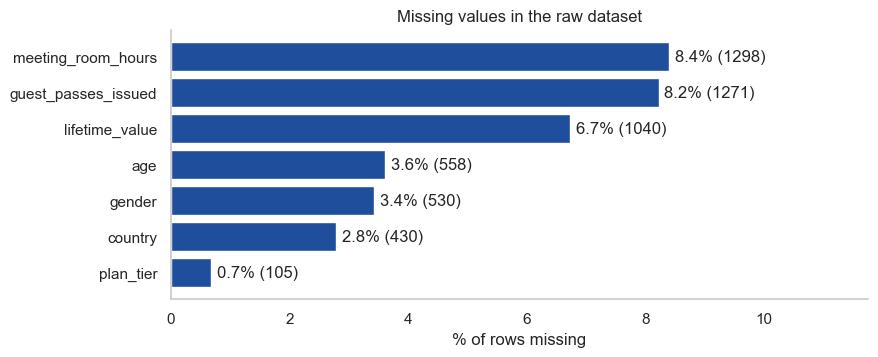

'Unknown', 'UNKNOWN' or 'unknown' in industry (missing value in disguise): 696 (4.5% of observations)


In [8]:
missing = (df_raw.isna().mean()*100).sort_values()   #Percentages of missing values
missing = missing[missing > 0]
missing_count = df_raw.isna().sum()   #Count of missing values
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(missing.index, missing.values, color=STATUS_COLORS["active"])

for i, (col, v) in enumerate(missing.items()):
    ax.text(v + 0.1, i, f"{v:.1f}% ({missing_count[col]})", va="center")

ax.set(xlabel="% of rows missing", xlim=(0, missing.max()*1.4), title="Missing values in the raw dataset")
ax.grid(False)
sns.despine()
plt.show()
unknown = (df_raw["industry"].str.lower() == "unknown").sum()
print(f"'Unknown', 'UNKNOWN' or 'unknown' in industry (missing value in disguise): {unknown} ({unknown/len(df_raw):.1%} of observations)")

`industry` has no empty cells, but 696 rows hold `Unknown`, which is a missing value in disguise. Missing `meeting_room_hours` (904 rows) and `guest_passes_issued` (1067 rows) can be read as 0 when the matching `uses_...` flag is False. With the flag True (394 and 204 rows) the value is truly unknown.

In [9]:
rows_missing = df_raw.isna().sum(axis=1).value_counts().sort_index().to_frame(name='count')
rows_missing['%'] = rows_missing['count']/len(df_raw)*100
print("Distribution of missing values per row:")
display(rows_missing.round(2))

Distribution of missing values per row:


,count,%
0,11096,71.75
1,3584,23.17
2,707,4.57
3,78,0.50


11096 rows have no missing values.

In [10]:
# Comparing records without member_id to catch possible duplicate members with different ids:
columns_without_id = [c for c in df_raw.columns if c != "member_id"]
without_repeated_ids = df_raw.drop_duplicates(subset="member_id")
print(f"repeated member_id: {df_raw['member_id'].duplicated().sum()}")
print(f"rows identical in every column except member_id: {without_repeated_ids[columns_without_id].duplicated().sum()}")

# Checking if the rows with the same member_id are identical in every column:
repeated = df_raw[df_raw["member_id"].duplicated(keep=False)]
columns_that_differ = (repeated.groupby("member_id").nunique(dropna=False).max() > 1).sum()
assert columns_that_differ == 0   # If this passes, rows with the same member_id are duplicates and can be removed

repeated member_id: 15
rows identical in every column except member_id: 167


There are 15 rows that have member_id duplicated and those rows are equal in every column so its exactly the same record, so those will be eliminated later. Out of the remaining rows, there are 167 rows where the member_id is different but all the other columns are the same so later we will also eliminate those.

In [11]:
ltv_text = df_raw["lifetime_value"].astype("string")
print(f"lifetime_value with a currency symbol: {ltv_text.str.contains('€', regex=False).sum()}")
print(f"lifetime_value with a thousands separator: {ltv_text.str.contains(',', regex=False).sum()}")

proof = []
for col in date_features:
    s = df_raw[col].str.strip()
    # Split only slash-formatted dates to check whether the day comes first.
    parts = s[s.str.contains("/", regex=False)].str.split("/", expand=True).astype(int)
    proof.append({"column": col, "DD/MM/YYYY": len(parts), "first number > 12": (parts[0] > 12).sum(),
                  "second number > 12": (parts[1] > 12).sum()})
    assert (parts[1] > 12).sum() == 0, f"{col}: day-first reading would be wrong"
display(pd.DataFrame(proof))
print("The second number is never above 12, so slash dates are day-first.")

lifetime_value with a currency symbol: 291
lifetime_value with a thousands separator: 110


,column,DD/MM/YYYY,first number > 12,second number > 12
0,membership_start,639,368,0
1,membership_end,463,278,0
2,last_badge_swipe,639,442,0


The second number is never above 12, so slash dates are day-first.


A few of the lifetime_values have the currency symbol which causes the column dtype to be object instead of float. 110 lifetime_values have a thousands separator and that can cause some issues, might be worthy to keep an eye in these. Slash dates are always day-first.

**Membership status and reference date.** The file has no extraction date. `membership_end = 1970-01-01` is read as "no end date", which marks a member as active. This is an interpretation: it means there is no recorded end, not that the member still attends. For active members, `last_badge_swipe + days_since_last_visit` should land on the extraction date, which gives a reference date.

In [12]:
dates_raw = df_raw[date_features].apply(parse_mixed_dates)
is_active_raw=(dates_raw['membership_end'] == pd.Timestamp('1970-01-01'))
days_raw = df_raw['days_since_last_visit']
implied_date = dates_raw['last_badge_swipe'] + pd.to_timedelta(days_raw, unit='D')  #Add the days since the last visit to recover the implied end or reference date

valid = (days_raw != 999) & (days_raw >= 0) & implied_date.notna() # No invalid or placeholder values
valid_active = valid & is_active_raw #active members

reference_date = implied_date[valid_active].mode()[0] # the most common implied date among active members is used as the dataset reference date
active_match = (implied_date[valid_active] == reference_date).mean()
valid_former = valid & ~is_active_raw & dates_raw["membership_end"].notna() # former(ended) members
former_match = (implied_date[valid_former] == dates_raw.loc[valid_former, 'membership_end']).mean()

last_real_end = dates_raw.loc[~is_active_raw, "membership_end"].max() # comparing reference date and latest membership end

print(f"Memberships with end date 1970-01-01 (potentially active): {is_active_raw.sum()} ({is_active_raw.mean():.1%})")
print(f"Inferred reference date: {reference_date.date()}")
print(f"For potentially active members, last_badge_swipe + days_since_last_visit is equal to the reference date in {active_match:.1%} of valid observations.")
print(f"For former members, last_badge_swipe + days_since_last_visit is equal to membership_end in {former_match:.1%} of valid observations.")
print(f"Latest recorded membership_end: {last_real_end.date()}")


active_gap = (implied_date[valid_active] - reference_date).dt.days #How far the rows that do not match are from the expected date
former_gap = (implied_date[valid_former] - dates_raw.loc[valid_former, "membership_end"]).dt.days
large_gap_index = active_gap[active_gap.abs() > 1].index.union(former_gap[former_gap.abs() > 1].index)

# The other date rules applied in Section 3.3:
start_raw, end_raw, swipe_raw = (dates_raw[c] for c in date_features)
date_conflict = (swipe_raw < start_raw) | (swipe_raw > reference_date) | (~is_active_raw & ((swipe_raw > end_raw) | (end_raw < start_raw)))

print(f"Within one day away from 2024-01-01: active {(active_gap.abs() <= 1).mean():.1%}, former {(former_gap.abs() <= 1).mean():.1%}")
print(f"Gap above one day: active {(active_gap.abs() > 1).sum()}, former {(former_gap.abs() > 1).sum()}, "
      f"total {len(large_gap_index)} ({len(large_gap_index) / valid.sum():.1%} of valid observations)")
print(f"Of those, also breaking another date rule: {date_conflict[large_gap_index].sum()}")

Memberships with end date 1970-01-01 (potentially active): 3956 (25.6%)
Inferred reference date: 2024-01-01
For potentially active members, last_badge_swipe + days_since_last_visit is equal to the reference date in 92.0% of valid observations.
For former members, last_badge_swipe + days_since_last_visit is equal to membership_end in 93.7% of valid observations.
Latest recorded membership_end: 2024-01-01
Within one day away from 2024-01-01: active 98.6%, former 97.8%
Gap above one day: active 51, former 234, total 285 (2.0% of valid observations)
Of those, also breaking another date rule: 218


The file has no extraction date, so we infer one. For members with `membership_end = 1970-01-01`, read as "no recorded end", `last_badge_swipe + days_since_last_visit` lands on 2024-01-01 for 92.0% of valid rows and within one day for 98.6%. This date also equals the latest real `membership_end`, so we use it as the reference date. For former members, the same sum matches `membership_end` in 93.7% of valid rows, which shows that `days_since_last_visit` counts to the end date for them.

One-day differences are too small to affect tenure or recency. Larger gaps affect 285 valid rows (2.0%) and 218 of them also break another date rule. We cannot tell which field is wrong in these rows, so they are removed in Section 3.3.

In [13]:

plan_names = {tier.replace("_", ""): tier for tier in TIER_ORDER}
# Removing spaces and punctuation so variants from the same plan names can be matched:
plan_key = df_raw["plan_tier"].str.lower().str.replace(r"[^a-z]", "", regex=True).map(plan_names).fillna("no plan")
days_per_plan = pd.crosstab(plan_key, df_raw["plan_days_per_week"]).reindex(TIER_ORDER + ["no plan"])
days_per_plan.index.name = "plan"
display(days_per_plan.replace(0, ""))

valid_plan_days = df_raw["plan_days_per_week"].between(1, 7)
values_per_plan = df_raw[valid_plan_days & df_raw["plan_tier"].notna()].groupby(plan_key)["plan_days_per_week"].nunique()
print(f"plans with a single valid number of days: {(values_per_plan == 1).sum()} of {len(values_per_plan)}")

plan_days_per_week,0,2,3,5,7,9
plan,,,,,,
hot_desk,14,5186,,,,15
flex,20,,5411,,,22
dedicated_desk,3,,,1543,,6
full_time,5,,,2460,,10
private_office,1,,,,663,1
no plan,,,,49,56,


plans with a single valid number of days: 5 of 5


Apart from the impossible values 0 and 9, each plan has a single number of days per week: `hot_desk` 2, `flex` 3, `dedicated_desk` and `full_time` 5 and `private_office` 7. This means the plan tells us the correct number of days for the 97 rows with 0 or 9, so they can be recovered in Section 3.4. The reverse only works in part: the 56 rows without a plan and with 7 days can only be `private_office`, so their plan is inferred in Section 3.2, while the 49 with 5 days could be `dedicated_desk` or `full_time`, so they are removed there.

In [14]:
start, end, swipe = (dates_raw[c] for c in date_features)
ltv_raw = parse_ltv(df_raw["lifetime_value"])
real_end = ~is_active_raw # Filter for former members

# correct labels for categories, used to count the rows that are written differently
standard_labels = {
    "gender": ["Female", "Male", "Other"],
    "country": ["Portugal", "Germany", "United Kingdom", "Spain", "France", "Netherlands", "Ireland", "Other (Europe)"],
    "industry": ["Information Technology", "Consulting", "Design & Creative", "Marketing & PR", "Finance", "Legal",
                 "Education", "Health", "Real Estate", "Unknown", "Other"],
    "plan_tier": TIER_ORDER,
}
# Mark rows where any category differs from its standard spelling
non_standard_label = pd.concat([df_raw[c].notna() & ~df_raw[c].isin(labels) for c, labels in standard_labels.items()], axis=1).any(axis=1)
slash_date = df_raw[date_features].apply(lambda s: s.str.contains("/", regex=False)).any(axis=1)

audit = {
    # Duplicates
    "repeated member_id (exact copies)": df_raw["member_id"].duplicated().sum(),
    "identical in every column except member_id": without_repeated_ids[columns_without_id].duplicated().sum(),
    # Categories
    "at least one category label written differently": non_standard_label.sum(),
    "industry 'Unknown', 'UNKNOWN' or 'unknown'": unknown,
    # Missing values
    "age missing": missing_count["age"],
    "gender missing": missing_count["gender"],
    "country missing": missing_count["country"],
    "meeting_room_hours missing": missing_count["meeting_room_hours"],
    "guest_passes_issued missing": missing_count["guest_passes_issued"],
    "lifetime_value missing": missing_count["lifetime_value"],
    # Formats
    "lifetime_value with a currency symbol": ltv_text.str.contains("€", regex=False).sum(),
    "lifetime_value with a thousands separator": ltv_text.str.contains(",", regex=False).sum(),
    "at least one date in DD/MM/YYYY": slash_date.sum(),
    "uses_print stored as 0/1 instead of boolean": len(df_raw),
    # Age and plan
    "age below 18": (df_raw["age"]<18).sum(),
    "age above 80": (df_raw["age"]>80).sum(),
    "n_colleagues_on_account below 0": (df_raw["n_colleagues_on_account"]<0).sum(),
    "plan_tier missing, knowing that plan_days_per_week is 100% filled": df_raw["plan_tier"].isna().sum(),
    "plan_days_per_week below 1": (df_raw["plan_days_per_week"] < 1).sum(),
    "plan_days_per_week above 7": (df_raw["plan_days_per_week"] > 7).sum(),
    # Dates
    "membership_end = 1970-01-01 (no recorded end)": is_active_raw.sum(),
    "membership_end before membership_start": (real_end & (end < start)).sum(),
    "last_badge_swipe before membership_start": (swipe < start).sum(),
    "last_badge_swipe after membership_end": (real_end & (swipe > end)).sum(),
    "last_badge_swipe after the reference date": (swipe > reference_date).sum(),
    "last_badge_swipe + days_since_last_visit more than one day off": len(large_gap_index),
    # Visits
    "days_since_last_visit = 999": (days_raw == 999).sum(),
    "days_since_last_visit negative": (days_raw < 0).sum(),
    "total_visits negative": (df_raw["total_visits"] < 0).sum(),
    "total_visits below actual_visits_last_period": (df_raw["total_visits"] < df_raw["actual_visits_last_period"]).sum(),
    "avg_weekly_visits negative": (df_raw["avg_weekly_visits"] < 0).sum(),
    "avg_weekly_visits above 7": (df_raw["avg_weekly_visits"] > 7).sum(),
    "entitled_visits_last_period negative": (df_raw["entitled_visits_last_period"] < 0).sum(),
    "actual_visits_last_period negative": (df_raw["actual_visits_last_period"] < 0).sum(),
    # Hours, passes, renewals and value
    "meeting_room_hours negative": (df_raw["meeting_room_hours"] < 0).sum(),
    "event_space_hours negative": (df_raw["event_space_hours"] < 0).sum(),
    "guest_passes_issued negative": (df_raw["guest_passes_issued"] < 0).sum(),
    "n_renewals negative": (df_raw["n_renewals"] < 0).sum(),
    "lifetime_value <= 0": (ltv_raw <= 0).sum(),
    # Inconsistencies between "uses_..." and their associated features
    "meeting_rooms inconsistency": (((df_raw["uses_meeting_rooms"] == True) & (df_raw["meeting_room_hours"] <= 0)) |
    ((df_raw["uses_meeting_rooms"] == False) & (df_raw["meeting_room_hours"] > 0))).sum(),
    "event_space inconsistency": (((df_raw["uses_event_space"] == True) & (df_raw["event_space_hours"] <= 0)) |
    ((df_raw["uses_event_space"] == False) & (df_raw["event_space_hours"] > 0))).sum(),
    "guest_passes inconsistency": (((df_raw["uses_guest_passes"] == True) & (df_raw["guest_passes_issued"] <= 0)) |
    ((df_raw["uses_guest_passes"] == False) & (df_raw["guest_passes_issued"] > 0))).sum(),
}
audit_table = pd.Series(audit, name='rows').to_frame()
audit_table['% of rows'] = (audit_table['rows']/len(df_raw)*100).round(2)
display(audit_table)

,rows,% of rows
repeated member_id (exact copies),15,0.10
identical in every column except member_id,167,1.08
at least one category label written differently,3242,20.96
"industry 'Unknown', 'UNKNOWN' or 'unknown'",696,4.50
age missing,558,3.61
gender missing,530,3.43
country missing,430,2.78
meeting_room_hours missing,1298,8.39
guest_passes_issued missing,1271,8.22
lifetime_value missing,1040,6.72


Each row of this table counts how many rows of the raw data break one rule and it summarises everything found in this section. The rules that compare with `membership_end` only look at members who have a real end date, because for the others that column is the 1970-01-01 placeholder. All the other rules look at every member. A row can break more than one rule, so the counts should not be added up.

Duplicates: 15 rows repeat a `member_id` and are exact copies. Among the remaining rows, 167 are identical to another row in every column except `member_id`.

Categories and missing values: 3242 rows (20.96%) have at least one category label written differently and `industry` holds `Unknown` in 696 rows (4.5%), a missing value in disguise. The other gaps are in `meeting_room_hours` (1298), `guest_passes_issued` (1271), `lifetime_value` (1040), `age` (558), `gender` (530) and `country` (430).

Formats: `lifetime_value` has a currency symbol in 291 rows and a thousands separator in 110. 639 rows have at least one date in DD/MM/YYYY. `uses_print` is stored as 0/1 in every row.

Age and plan: 98 members are younger than 18 and 53 are older than 80. `n_colleagues_on_account` is negative in 566 rows (3.66%). `plan_tier` is missing in 105 rows even though `plan_days_per_week` is always filled. `plan_days_per_week` is below 1 in 43 rows and above 7 in 54, which are not possible numbers of days in a week.

Dates: `membership_end` is the 1970-01-01 placeholder in 3956 rows (25.58%). Among the members who have ended, `membership_end` is before `membership_start` in 152 rows and `last_badge_swipe` is after `membership_end` in 213. In 152 of those 213 rows `membership_end` is also before `membership_start`, which points to an error in the end date rather than to real visits after leaving. `last_badge_swipe` is before `membership_start` in 94 rows (all members) and after the reference date (2024-01-01) in 34. `last_badge_swipe + days_since_last_visit` is more than one day away from the expected date in 285 rows. Rows with these conflicts are removed in Section 3.3.

Visits: `days_since_last_visit` is 999, a placeholder, in 1298 rows (8.39%) and negative in 56. `total_visits` is negative in 42 rows and lower than `actual_visits_last_period` in 1172 (7.58%), which should not happen because the total includes the last period. `avg_weekly_visits` is above 7 in 42 rows. There are no negative values in `avg_weekly_visits`, `entitled_visits_last_period` or `actual_visits_last_period`.

Hours, passes, renewals and value: `meeting_room_hours` is negative in 16 rows, `event_space_hours` in 8, `guest_passes_issued` in 7 and `n_renewals` in 66. `lifetime_value` is zero or negative in 1825 rows (11.8%).

Inconsistencies with the `uses_...` flags: a row is inconsistent when the flag is True but the quantity is 0 or less, or when the flag is False but the quantity is above 0. This happens in 78 rows for meeting rooms, 79 for event space and 131 for guest passes. The other `uses_...` flags have no quantity column to compare with.

## 3. Data Preparation: cleaning
Rows are removed in three cases: duplicates (Section 3.1), rows whose plan cannot be determined (Section 3.2) and date conflicts (Section 3.3). Otherwise, invalid values become missing or are recovered from another field and a `flag_` column records every change so each decision can be reversed.

### 3.1 Duplicates
Rows that repeat a `member_id` are exact copies and are removed. Besides those, some rows are identical in all 30 other columns and differ only in `member_id`. They are treated as the same member registered twice.

In [15]:
df = df_raw.drop_duplicates(subset="member_id").copy()
repeated_ids_removed = len(df_raw) - len(df)
df = df.drop_duplicates(subset=columns_without_id).copy()
print(f"rows: {len(df_raw)} -> {len(df)}")
print(f"exact duplicate rows removed: {repeated_ids_removed} | identical rows (except member_id) removed: {len(df_raw) - repeated_ids_removed - len(df)}")

rows: 15465 -> 15283
exact duplicate rows removed: 15 | identical rows (except member_id) removed: 167


### 3.2 Categories
Spelling variants are mapped to one label. `Unknown` in `industry` becomes missing and `flag_industry_unknown` records which rows had it. Rows without a plan and with 7 days per week become `private_office`, the only plan with 7 days (Section 2.3) and `flag_plan_inferred` records them. Rows without a plan and with 5 days are removed: that number of days fits both `dedicated_desk` and `full_time`, so the plan cannot be inferred, they are too few to affect the analysis.

In [16]:
def standardise(series, mapping, name, replace_spaces=False):
    values = series.str.strip().str.lower()
    if replace_spaces:
        values = values.str.replace(' ', '_')
    # Converting the variants to the same standard category
    result = values.map(mapping)
    print(f"{name}: {series.nunique()} -> {result.nunique()} categories")
    return result

gender_mapping = {'female': 'Female', 'f': 'Female', 'male': 'Male', 'm': 'Male', 'other': 'Other', 'o': 'Other'}
country_mapping = {
    "portugal": "Portugal", "pt": "Portugal", "portucal": "Portugal",
    "germany": "Germany", "de": "Germany", "deutschland": "Germany",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "gb": "United Kingdom", "u.k.": "United Kingdom",
    "spain": "Spain", "es": "Spain", "españa": "Spain", "espana": "Spain",
    "france": "France", "fr": "France",
    "netherlands": "Netherlands", "the netherlands": "Netherlands", "nl": "Netherlands", "holland": "Netherlands",
    "ireland": "Ireland", "ie": "Ireland", "other (europe)": "Other (Europe)"}
industry_mapping = {
    'information technology': 'Information Technology', 'it': 'Information Technology', 'tech': 'Information Technology',
    "consulting": "Consulting",
    "design & creative": "Design & Creative", "design/creative": "Design & Creative", "design and creative": "Design & Creative",
    "marketing & pr": "Marketing & PR", "marketing/pr": "Marketing & PR", "marketing and pr": "Marketing & PR",
    "finance": "Finance", "legal": "Legal", "education": "Education", "health": "Health",
    "real estate": "Real Estate", "realestate": "Real Estate", "real-estate": "Real Estate",
    "unknown": "Unknown", "other": "Other"}
plan_mapping = {
    "flex": "flex", "hot_desk": "hot_desk", "hotdesk": "hot_desk",
    "dedicated_desk": "dedicated_desk", "dedicateddesk": "dedicated_desk",
    "full_time": "full_time", "fulltime": "full_time",
    "private_office": "private_office", "privateoffice": "private_office"}

raw_categories = df[['gender', 'country', 'industry', 'plan_tier']].copy()
df['gender'] = standardise(df['gender'], gender_mapping, "gender")
df["country"] = standardise(df["country"], country_mapping, "country")
df["industry"] = standardise(df["industry"], industry_mapping, "industry")
df["plan_tier"] = standardise(df["plan_tier"], plan_mapping, "plan_tier", replace_spaces=True)

changed = (raw_categories.notna() & (raw_categories != df[raw_categories.columns])).any(axis=1)
df['flag_industry_unknown'] = (df['industry'] == 'Unknown')
df.loc[df['flag_industry_unknown'], 'industry'] = np.nan
print(f"\nrows with at least one label changed: {changed.sum()} ({changed.mean():.1%})")
print(f"'Unknown', 'UNKNOWN' or 'unknown' industry set to missing: {df['flag_industry_unknown'].sum()}")

# Only private_office has 7 days per week (Section 2.3)
df["flag_plan_inferred"] = df["plan_tier"].isna() & (df["plan_days_per_week"] == 7)
df.loc[df["flag_plan_inferred"], "plan_tier"] = "private_office"
print(f"plan inferred as private_office: {df['flag_plan_inferred'].sum()} | still without a plan: {df['plan_tier'].isna().sum()}")

gender: 12 -> 3 categories
country: 33 -> 8 categories


industry: 43 -> 11 categories
plan_tier: 19 -> 5 categories

rows with at least one label changed: 3236 (21.2%)
'Unknown', 'UNKNOWN' or 'unknown' industry set to missing: 687
plan inferred as private_office: 54 | still without a plan: 49


In [17]:
# The rows with 5 days in plan_days_per_week don't have a plan (it could fit both dedicated_desk and full_time)
no_plan = df["plan_tier"].isna()
assert (df.loc[no_plan, "plan_days_per_week"] == 5).all(), "a row without a plan does not have 5 days per week"
print(f"rows without a plan removed: {no_plan.sum()} ({no_plan.mean():.1%})")
df = df[~no_plan].copy()  # removes the rows without a plan
print(f"rows now: {len(df)}")

rows without a plan removed: 49 (0.3%)
rows now: 15234


### 3.3 Dates, status and membership duration
Dates are parsed with explicit formats. Rows with a date conflict are removed: membership duration (also called *tenure*) and recency cannot be trusted in them and we can't tell which field is wrong. A row has a conflict when any of these holds:

- `membership_end` is before `membership_start`
- `last_badge_swipe` is before `membership_start`, after `membership_end` or after the reference date
- `days_since_last_visit` is negative
- `last_badge_swipe + days_since_last_visit` is more than one day away from `membership_end`, or from the reference date for active members

Rows with `days_since_last_visit` = 999 cannot be tested with the last rule; they stay unless they break another one. `membership_months` measures the membership duration from `membership_start` to `membership_end`, or to the reference date for active members.

In [18]:
for col in date_features:
    df[col] = parse_mixed_dates(df[col])
assert df[date_features].isna().sum().sum() == 0

df['is_active'] = df['membership_end'] == pd.Timestamp('1970-01-01')
df['status'] = np.where(df['is_active'], 'active', 'ended')
# Replace the 1970 placeholder with a missing end date for active members
df['membership_end'] = df['membership_end'].mask(df['is_active'])

# last_badge_swipe + days_since_last_visit should land on the end date or on the reference date for active members
tenure_end = df['membership_end'].fillna(reference_date)
days_testable = (df['days_since_last_visit'] != 999) & (df['days_since_last_visit'] >= 0)
implied_end = df['last_badge_swipe'] + pd.to_timedelta(df['days_since_last_visit'], unit='D')
days_gap = (implied_end - tenure_end).dt.days.where(days_testable)

date_conflicts = pd.DataFrame({
    "membership_end before membership_start": df['membership_end'] < df['membership_start'],
    'last_badge_swipe before membership_start': df['last_badge_swipe'] < df['membership_start'],
    "last_badge_swipe after membership_end": df["last_badge_swipe"] > df["membership_end"],
    "last_badge_swipe after the reference date": df["last_badge_swipe"] > reference_date,
    "days_since_last_visit negative": df["days_since_last_visit"] < 0,
    "days_since_last_visit more than one day off": days_gap.abs() > 1,
})
# a row is removed if at least one of the date checks fails
has_date_conflict = date_conflicts.any(axis=1)
print(date_conflicts.sum().to_string())
print(f"\nrows removed, breaking at least one rule: {has_date_conflict.sum()} ({has_date_conflict.mean():.1%})")
print(f"share of active members: {df.loc[has_date_conflict, 'is_active'].mean():.1%} of removed rows, {df.loc[~has_date_conflict, 'is_active'].mean():.1%} of the rows that stay")

df = df[~has_date_conflict].copy()
tenure_end = df['membership_end'].fillna(reference_date)
df["membership_months"] = (tenure_end - df["membership_start"]).dt.days / DAYS_PER_MONTH
assert (df["membership_months"] > 0).all(), "a remaining row has no positive tenure"

print(f"\nrows now: {len(df)}")
print(df["status"].value_counts().to_string())

membership_end before membership_start         148
last_badge_swipe before membership_start        93
last_badge_swipe after membership_end          209
last_badge_swipe after the reference date       33
days_since_last_visit negative                  55
days_since_last_visit more than one day off    282

rows removed, breaking at least one rule: 394 (2.6%)
share of active members: 17.5% of removed rows, 25.8% of the rows that stay

rows now: 14840
status
ended     11017
active     3823


### 3.4 Numeric and boolean fields
| Field | Treatment | Reason |
|---|---|---|
| `age` outside 18-80 | Missing | Values such as 1 or 149 are impossible for a member, and ages above 80 are too rare to trust in a coworking base |
| `uses_print` | Boolean | Same meaning as the other `uses_...` columns |
| `n_colleagues_on_account` = -1 | 0 for individual accounts, missing for team accounts | -1 is a placeholder |
| `plan_days_per_week` = 0 or 9 | Recovered from the plan | Each plan has a single number of days |
| Negative visits, hours, passes, renewals | Missing | Counts cannot be negative |
| `days_since_last_visit` = 999 | Recomputed from the dates | Almost all of these members have visits, so 999 does not mean "never visited" |
| Missing hours or passes, `uses_...` False | 0 | The service was not used |
| `total_visits` above 1000 or `avg_weekly_visits` above 7 | Flag only (`flag_visits_scale_error`) | These values look about 10 times too high, but this is still to be confirmed, so they are not corrected |
| `total_visits` below `actual_visits_last_period`; `uses_meeting_rooms` False with hours above 0 | Flag only | The fields contradict each other; still to investigate |

In [19]:
df["flag_age_invalid"] = (df["age"] < 18) | (df["age"] > 80)
df.loc[df["flag_age_invalid"], "age"] = np.nan

df["uses_print"] = df["uses_print"].astype(bool)


placeholder = (df['n_colleagues_on_account']==-1) # -1 means no colleagues for individual members, but it's unknown for team accounts
df['flag_colleagues_placeholder'] = placeholder
df.loc[placeholder & ~df['is_team_account'], 'n_colleagues_on_account'] = 0
df.loc[placeholder & df['is_team_account'], 'n_colleagues_on_account'] = np.nan

valid_days = df['plan_days_per_week'].between(1, 7)
# Check that each plan has a consistent number of days before recovering invalid values.
days_by_plan = df[valid_days].groupby('plan_tier')['plan_days_per_week'].agg(['min', 'max'])
assert (days_by_plan['min'] == days_by_plan['max']).all(), 'a plan has more than one number of days'
df['flag_plan_days_invalid'] = df['plan_days_per_week'].isin([0, 9])
df.loc[df["flag_plan_days_invalid"], "plan_days_per_week"] = df["plan_tier"].map(days_by_plan["max"])

for col in ["total_visits", "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals"]:
    df[f"flag_{col}_negative"] = df[col] < 0
    df.loc[df[f"flag_{col}_negative"], col] = np.nan

df["flag_days_since_999"] = df["days_since_last_visit"] == 999
recomputed = (df["membership_end"].fillna(reference_date) - df["last_badge_swipe"]).dt.days
df["days_since_last_visit"] = df["days_since_last_visit"].astype(float)
df.loc[df["flag_days_since_999"], "days_since_last_visit"] = recomputed

for use_col, value_col in [("uses_meeting_rooms", "meeting_room_hours"), ("uses_guest_passes", "guest_passes_issued")]:
    # Set missing usage to zero only when the service was not used and was not flagged negative.
    no_use = df[value_col].isna() & ~df[use_col] & ~df[f"flag_{value_col}_negative"]
    df.loc[no_use, value_col] = 0
    print(f"{value_col}: {no_use.sum()} missing values set to 0 because the service was not used; "
          f"{df[value_col].isna().sum()} remain missing")

df['flag_visits_scale_error'] = (df['total_visits'] > 1000) | (df['avg_weekly_visits'] > 7)
df["flag_visits_below_last_period"] = df['total_visits']<df['actual_visits_last_period']
df["flag_meeting_use_conflict"] = ~df["uses_meeting_rooms"] & (df["meeting_room_hours"] > 0)

summary = ["flag_age_invalid", "flag_colleagues_placeholder", "flag_plan_days_invalid", "flag_days_since_999",
           "flag_visits_scale_error", "flag_visits_below_last_period", "flag_meeting_use_conflict"]
print("\n" + df[summary].sum().to_string())
print(f"\ndays_since_last_visit recomputed for {(df['flag_days_since_999'] & df['days_since_last_visit'].notna()).sum()} of "
      f"{df['flag_days_since_999'].sum()} rows with 999")

meeting_room_hours: 866 missing values set to 0 because the service was not used; 393 remain missing
guest_passes_issued: 1016 missing values set to 0 because the service was not used; 199 remain missing



flag_age_invalid                  147
flag_colleagues_placeholder       546
flag_plan_days_invalid             95
flag_days_since_999              1244
flag_visits_scale_error            40
flag_visits_below_last_period    1086
flag_meeting_use_conflict          54

days_since_last_visit recomputed for 1244 of 1244 rows with 999


### 3.5 `lifetime_value`
String values are converted to numbers and negatives become missing. Zeros are read as unknown revenue, because their share barely changes with plan or activity and many belong to members with long, active memberships. Only zeros that are plausible stay at 0: at most 5 visits, under one month and no renewals.

In [20]:
df['lifetime_value'] = parse_ltv(df['lifetime_value'])
df['flag_ltv_negative'] = df['lifetime_value'] < 0
df.loc[df['flag_ltv_negative'], 'lifetime_value'] = np.nan

is_zero=(df['lifetime_value'] == 0)
# Keep zero revenue only for very recent, low-activity members with no renewals.
zero_plausible = is_zero & (df["total_visits"] <= 5) & (df["membership_months"] < 1) & (df['n_renewals'] == 0)
zero_active = is_zero & (df["total_visits"] >= 100) & (df["membership_months"] >= 12)
zero_by_plan = is_zero.groupby(df["plan_tier"]).mean().reindex(TIER_ORDER).mul(100).round(1)

# Compare the share of zeros across 5 groups of total visit counts
zero_by_visits = (is_zero.groupby(pd.qcut(df['total_visits'], 5, duplicates='drop'), observed=True).mean()*100).round(1)

print(f"zeros: {is_zero.sum()} | at least 100 visits and 12 months: {zero_active.sum()} | plausible: {zero_plausible.sum()}")
print("\n% of zeros per plan:\n" + zero_by_plan.to_string())
print("\n% of zeros per quintile of total_visits:\n" + zero_by_visits.to_string())

df['flag_ltv_zero_as_missing'] = is_zero & ~zero_plausible
df.loc[df["flag_ltv_zero_as_missing"], "lifetime_value"] = np.nan
print(f"\nzeros set to missing: {df['flag_ltv_zero_as_missing'].sum()} | missing lifetime_value now: {df['lifetime_value'].isna().sum()}")

zeros: 1673 | at least 100 visits and 12 months: 409 | plausible: 36

% of zeros per plan:
plan_tier
hot_desk          10.2
flex              11.2
dedicated_desk    11.6
full_time         12.9
private_office    13.1

% of zeros per quintile of total_visits:
total_visits
(-0.001, 6.0]      11.4
(6.0, 16.0]        13.5
(16.0, 68.0]       11.7
(68.0, 162.0]      10.3
(162.0, 6530.0]     9.4

zeros set to missing: 1637 | missing lifetime_value now: 2697


To identify possible scale errors, we compare each member's monthly revenue with the median monthly revenue of their plan, since reasonable values depend on both the plan and membership duration. We found no values between 20 and 50 times the plan median, while those above this range are mostly around 100 times higher. Most of these unusually high values are whole numbers, unlike the rest, which suggests that a decimal point may have been lost.

In [21]:
positive = (df["lifetime_value"] > 0) & (df["membership_months"] >= 1)
monthly = (df["lifetime_value"] / df["membership_months"]).where(positive)

plan_median = monthly.groupby(df["plan_tier"]).transform("median") # Comparison monthly revenue with the median of members on the same plan.
ratio = monthly / plan_median

bins = pd.cut(ratio, [0, 2, 5, 10, 20, 50, 80, 120, 200, np.inf])
display(bins.value_counts().sort_index().rename("rows").to_frame())

scale_error = ratio >= SCALE_RATIO_THRESHOLD
df["flag_ltv_scale_error"] = scale_error
is_integer = df["lifetime_value"] % 1 == 0
print(f"rows flagged: {scale_error.sum()} ({scale_error.mean():.2%})")
print(f"median ratio to the plan: {ratio[scale_error].median():.1f}x, or {(ratio[scale_error] / 100).median():.2f}x after dividing by 100")
print(f"whole-number values: {is_integer[scale_error].mean():.1%} of flagged rows vs {is_integer[positive & ~scale_error].mean():.1%} of other rows")
print(f"share of all recorded revenue held by flagged rows: {df.loc[scale_error, 'lifetime_value'].sum() / df['lifetime_value'].sum():.1%}")

,rows
"(0.0, 2.0]",10802
"(2.0, 5.0]",568
"(5.0, 10.0]",66
"(10.0, 20.0]",1
"(20.0, 50.0]",0
"(50.0, 80.0]",1
"(80.0, 120.0]",60
"(120.0, 200.0]",11
"(200.0, inf]",5


rows flagged: 77 (0.52%)
median ratio to the plan: 104.2x, or 1.04x after dividing by 100
whole-number values: 97.4% of flagged rows vs 2.2% of other rows
share of all recorded revenue held by flagged rows: 44.3%


In [22]:
def top_share(values, share):
    """Share of revenue held by the top members, among those with positive revenue."""
    values = values[values > 0].sort_values(ascending=False)
    return values.iloc[:int(np.ceil(len(values) * share))].sum() / values.sum()


ltv_before = df["lifetime_value"].copy()
# Apply the selected treatment only to rows flagged as likely scale errors.
if LTV_SCALE_TREATMENT == "divide":
    df.loc[scale_error, "lifetime_value"] = df.loc[scale_error, "lifetime_value"] / 100
elif LTV_SCALE_TREATMENT == "missing":
    df.loc[scale_error, "lifetime_value"] = np.nan
else:
    raise ValueError(LTV_SCALE_TREATMENT)

comparison = pd.DataFrame({
    "before": [top_share(ltv_before, 0.01), top_share(ltv_before, 0.10), ltv_before.mean(), ltv_before.median()],
    "after": [top_share(df["lifetime_value"], 0.01), top_share(df["lifetime_value"], 0.10), df["lifetime_value"].mean(), df["lifetime_value"].median()],
}, index=["revenue share of top 1%", "revenue share of top 10%", "mean", "median"]).round(3)
print(f"treatment: {LTV_SCALE_TREATMENT}")
display(comparison)

treatment: divide


,before,after
revenue share of top 1%,0.460,0.068
revenue share of top 10%,0.669,0.422
mean,7315.025,4104.180
median,1647.360,1610.810


### 3.6 Effect of the cleaning on missing values
Cleaning makes hidden gaps visible: placeholders, impossible values and most zeros in `lifetime_value` become missing. Other columns move the opposite way where a value could be recovered. `membership_end` is left out because its missing values now mean an active member.

,raw file,after cleaning
lifetime_value,6.7,18.2
age,3.6,4.5
industry,0.0,4.4
gender,3.4,3.4
country,2.8,2.7
meeting_room_hours,8.4,2.6
guest_passes_issued,8.2,1.3
n_colleagues_on_account,0.0,1.0
n_renewals,0.0,0.4
total_visits,0.0,0.3


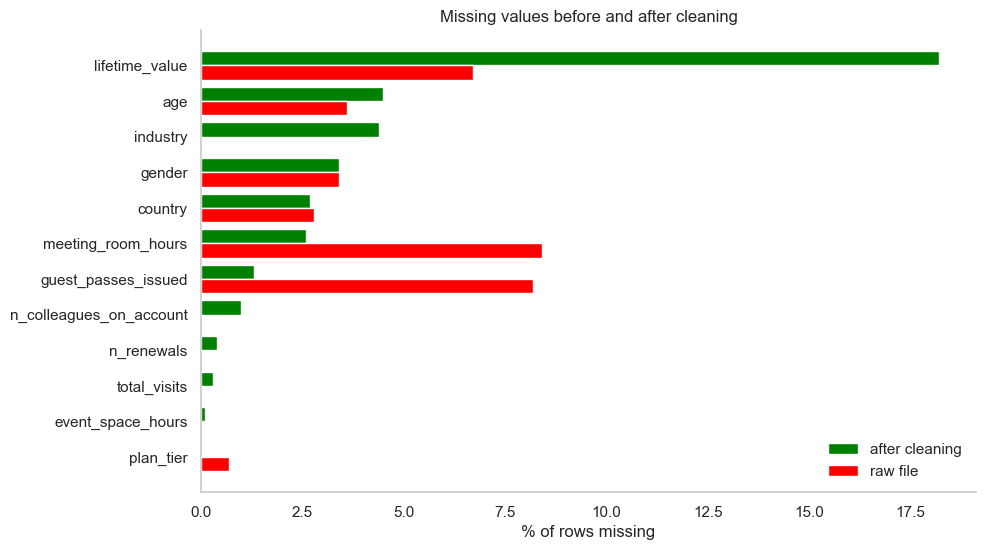

In [23]:
compare_columns = [c for c in df_raw.columns if c != "membership_end" and (df_raw[c].isna().any() or df[c].isna().any())]
missing_compare = pd.DataFrame({
    "raw file": df_raw[compare_columns].isna().mean().mul(100),
    "after cleaning": df[compare_columns].isna().mean().mul(100),
}).round(1).sort_values("after cleaning")
display(missing_compare.sort_values("after cleaning", ascending=False))

positions = np.arange(len(missing_compare))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(positions + 0.2, missing_compare["after cleaning"], height=0.4, color="green", label="after cleaning")
ax.barh(positions - 0.2, missing_compare["raw file"], height=0.4, color="red", label="raw file")
ax.set_yticks(positions, missing_compare.index)
ax.set(xlabel="% of rows missing", title="Missing values before and after cleaning")
ax.legend(frameon=False, loc="lower right")
ax.grid(False)
sns.despine()
plt.show()

## 4. Data Understanding: exploration of the cleaned data
### 4.1 Distributions

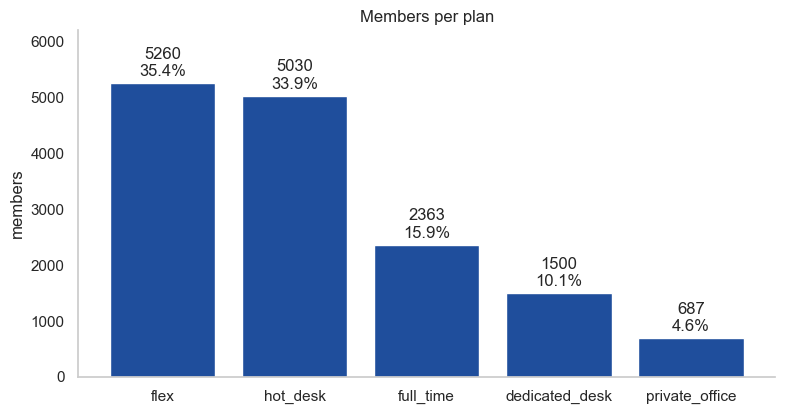

In [24]:
counts = df["plan_tier"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(counts.index, counts.values, color=STATUS_COLORS["active"])
ax.bar_label(bars, labels=[f"{v}\n{v / len(df):.1%}" for v in counts.values], padding=3)
ax.set(ylabel="members", title="Members per plan", ylim=(0, counts.max() * 1.18))
ax.grid(False)
sns.despine()
plt.show()

69.3% of the members are on the Flex and Hot desk plans, the two cheapest, but those plans account for only 33.1% of the known lifetime value (Section 4.4). Private Office, the most expensive plan, has only 4.6% of the members but 20.4% of the known lifetime value (Section 4.4).

#### Numeric distributions: histograms and boxplots

We examine the numeric variables from Section 2.2, plus `membership_months`, using the cleaned data. Histograms show the overall shape of each distribution, while boxplots show the median, quartiles and outliers. The following plots use the original scale.

In [25]:
# Summary of the numeric distributions, including the 1st and 99th percentiles:

distribution_features = metric_features + ["membership_months"]
display(df[distribution_features].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2))

,count,mean,std,min,1%,25%,50%,75%,99%,max
age,14166.0,34.73,8.31,18.00,19.00,29.00,34.00,40.00,55.00,74.00
n_colleagues_on_account,14698.0,0.58,1.15,0.00,0.00,0.00,0.00,1.00,5.00,9.00
plan_days_per_week,14840.0,3.37,1.41,2.00,2.00,2.00,3.00,5.00,7.00,7.00
days_since_last_visit,14840.0,37.71,61.45,0.00,1.00,4.00,11.00,44.00,290.61,391.00
total_visits,14798.0,110.03,183.10,0.00,1.00,8.00,35.00,131.00,694.00,6530.00
avg_weekly_visits,14840.0,1.77,1.93,0.00,0.04,0.71,1.41,2.40,5.32,47.40
entitled_visits_last_period,14840.0,27.44,13.45,0.00,2.65,17.39,26.09,43.48,60.87,78.27
actual_visits_last_period,14840.0,13.76,11.36,0.00,0.00,5.00,10.00,20.00,44.00,60.00
meeting_room_hours,14447.0,31.54,423.91,0.00,0.00,0.00,0.00,4.80,324.20,41220.00
event_space_hours,14832.0,5.19,26.22,0.00,0.00,0.00,0.00,0.00,126.20,602.80


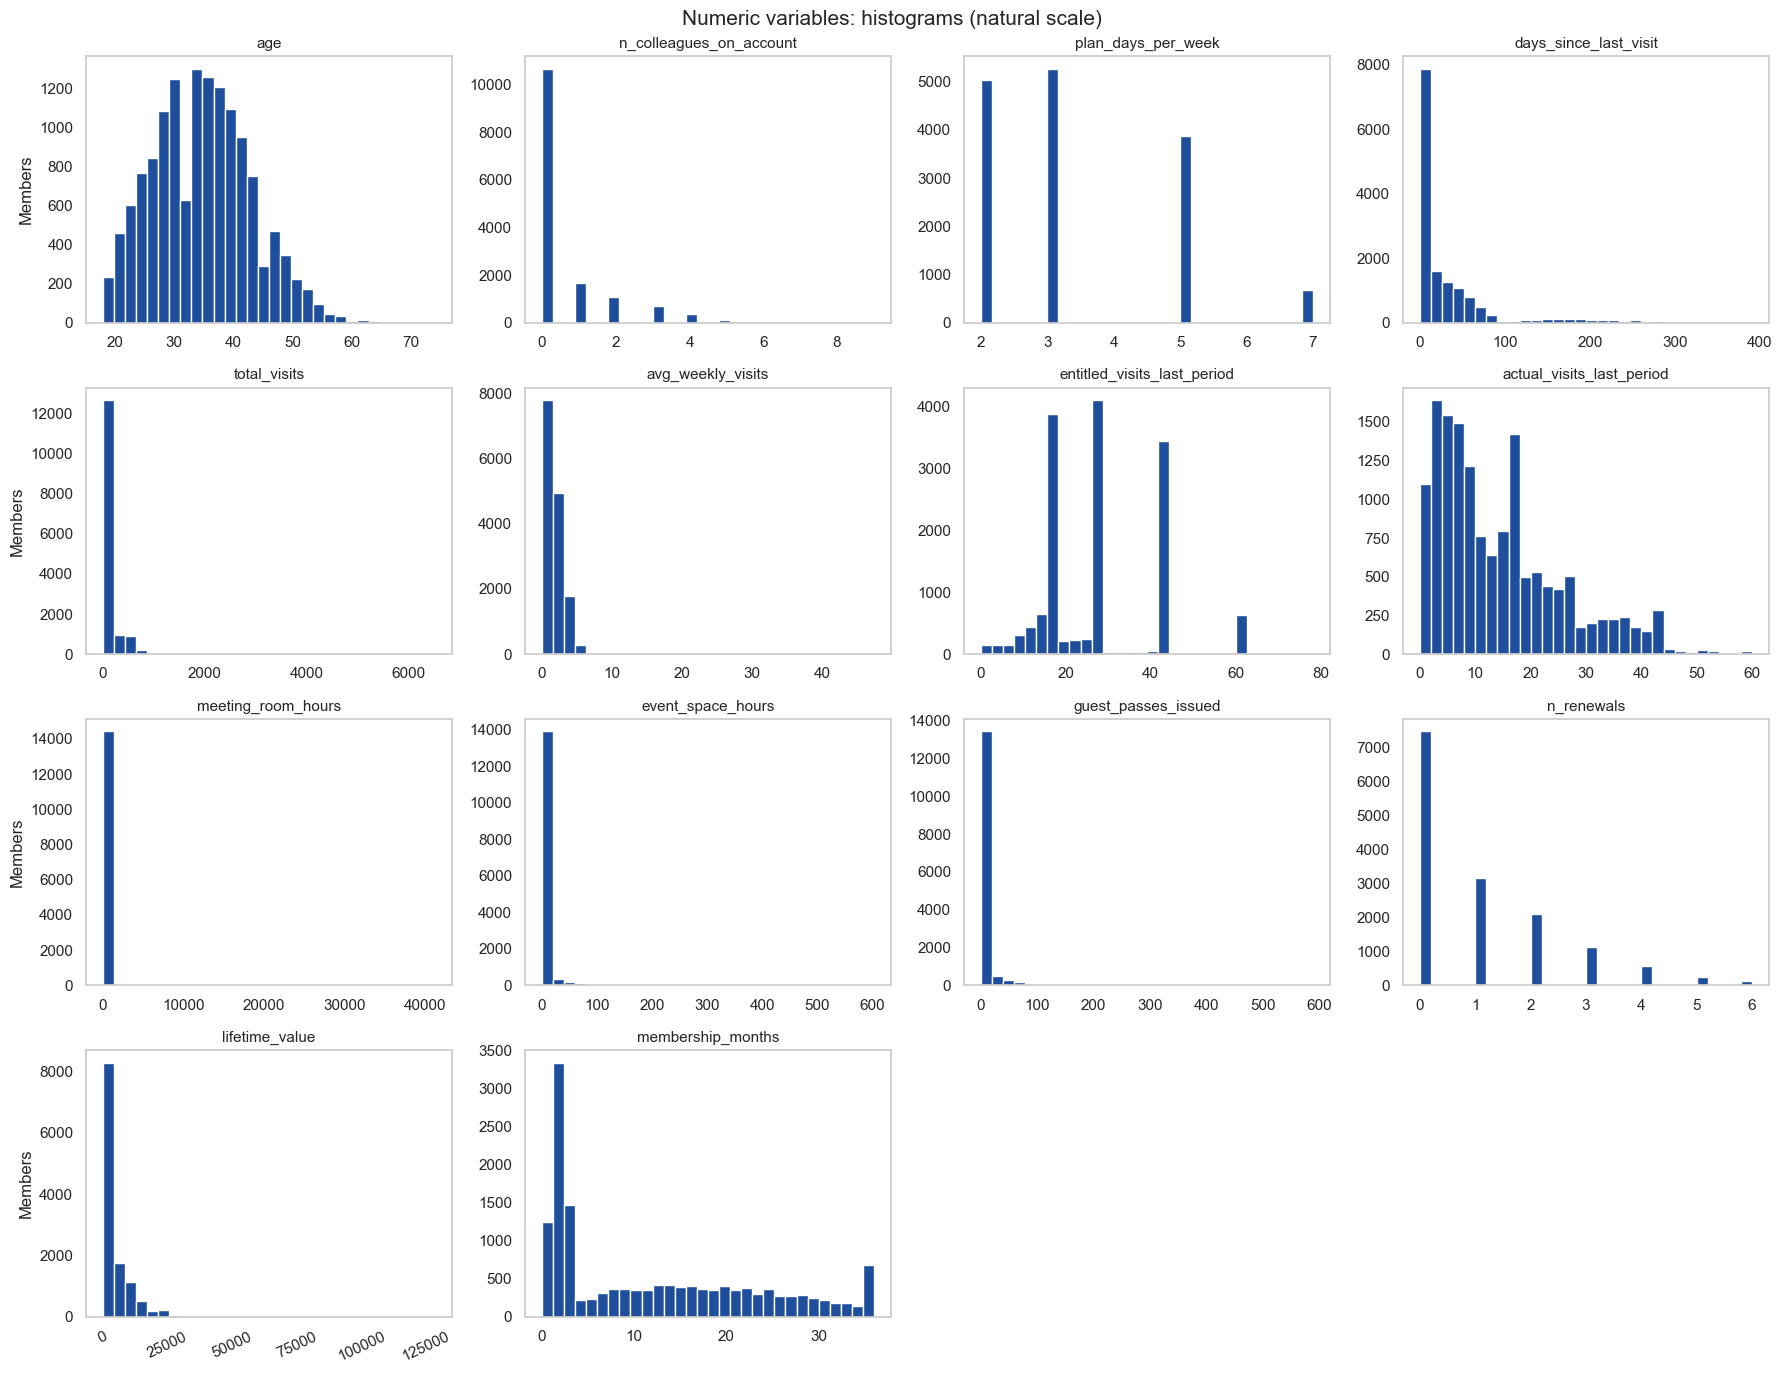

In [26]:
# Histograms of the numeric variables:
n_cols=4
n_rows=int(np.ceil(len(distribution_features)/n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18,3.5*n_rows))
flat_axes = axes.flatten()

for ax, col in zip(flat_axes, distribution_features):
    ax.hist(df[col].dropna(), bins=30, color=STATUS_COLORS["active"])
    ax.set_title(col, fontsize=11)
    ax.set_ylabel('')
    if col in distribution_features[0::4]:
        ax.set_ylabel('Members')
    ax.tick_params(axis='x')
    ax.grid(False)
    if df[col].max()>=100000:
        ax.tick_params(axis='x', labelrotation=25)

for ax in flat_axes[len(distribution_features):]:
    ax.set_visible(False)

fig.suptitle("Numeric variables: histograms (natural scale)", fontsize=15)
fig.tight_layout()
plt.show()

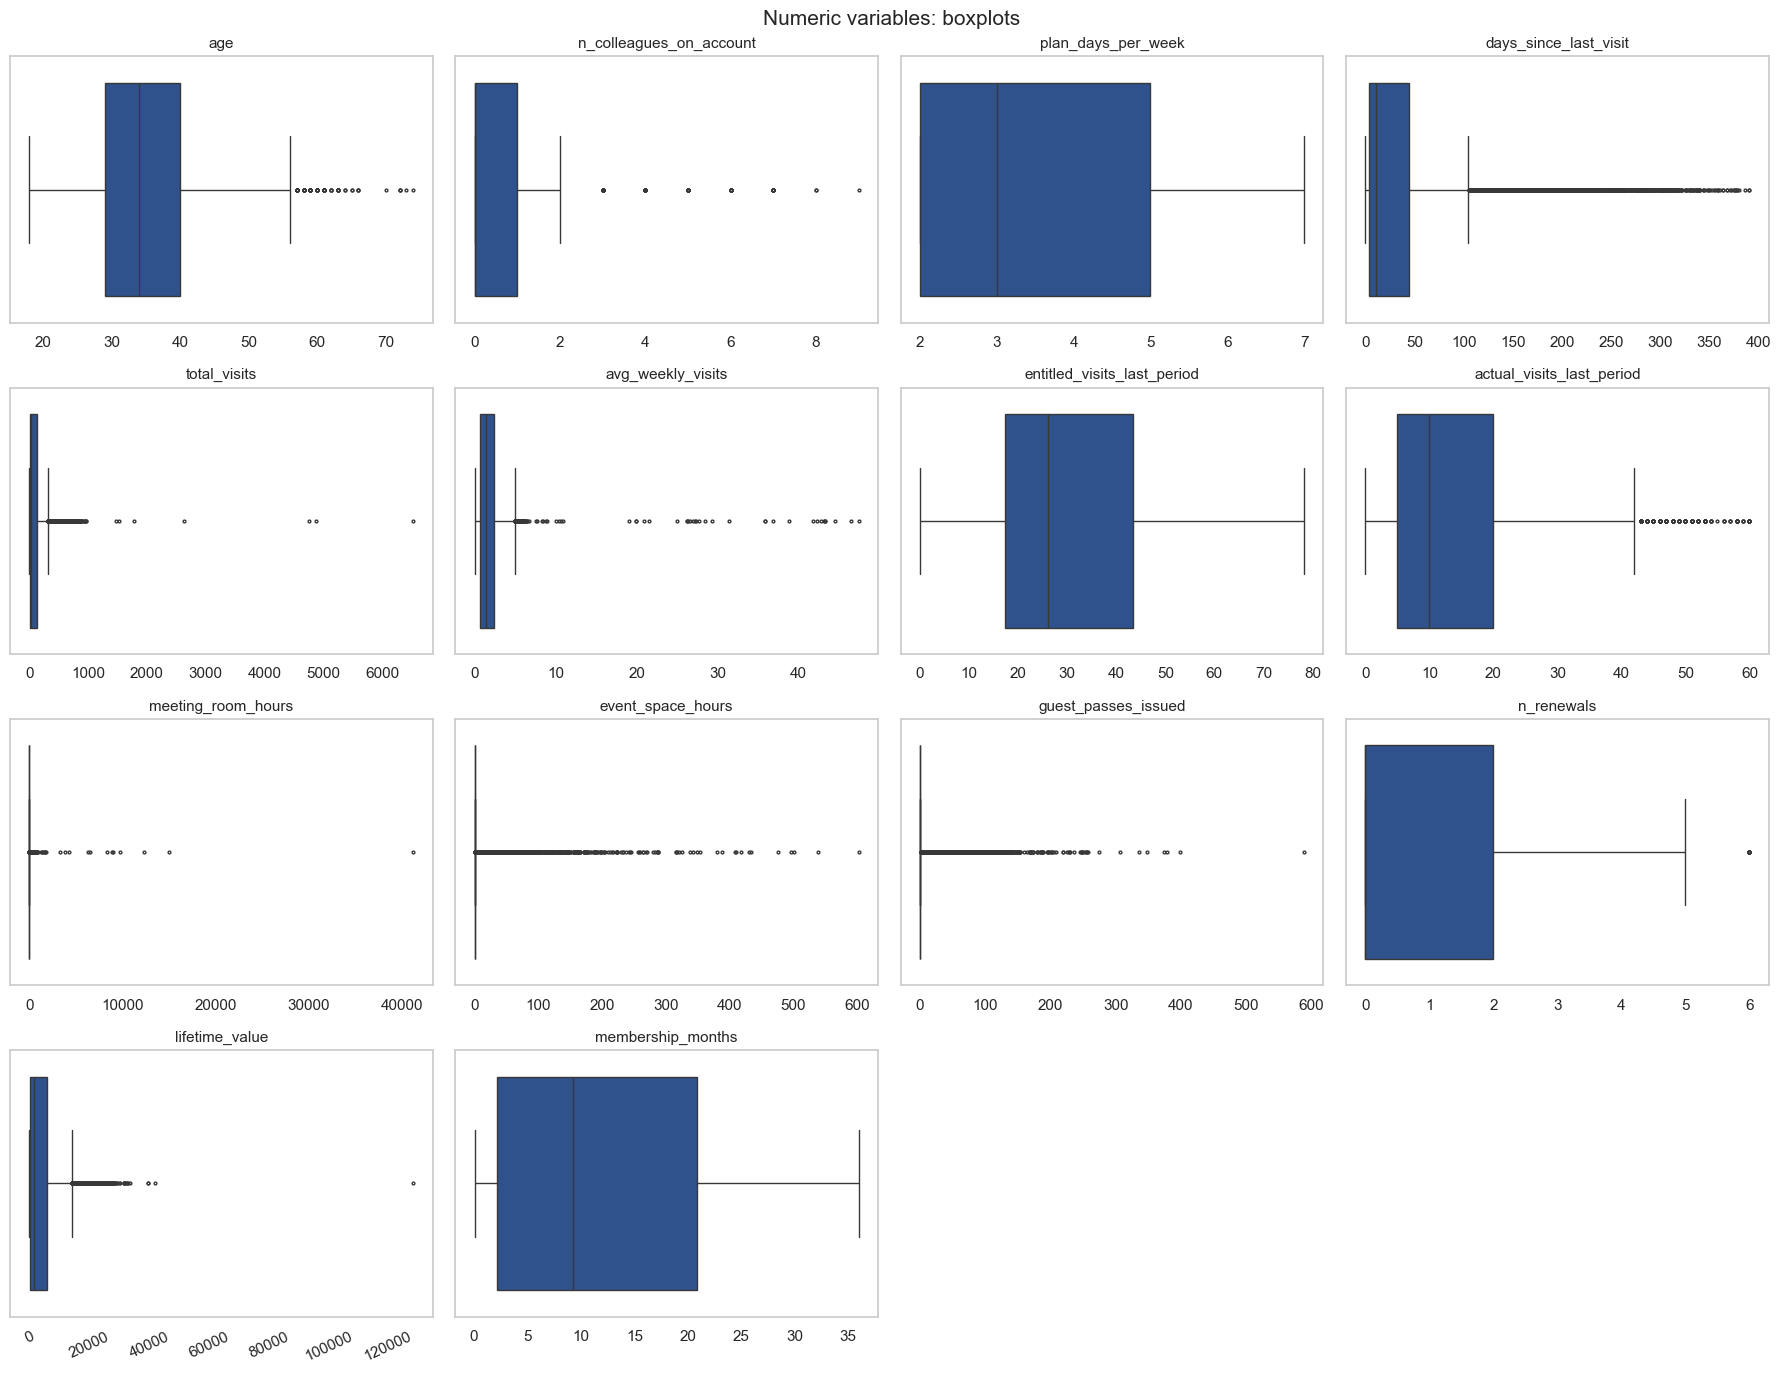

In [27]:
# Boxplots of numeric variables:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18,3.5*n_rows))
flat_axes = axes.flatten()

for ax, col in zip(flat_axes, distribution_features):
    sns.boxplot(x=df[col].dropna(), ax=ax, color=STATUS_COLORS["active"], fliersize=2)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="x")
    ax.grid(False)
    if df[col].max()>=100000:
        ax.tick_params(axis="x", labelrotation=25)


for ax in flat_axes[len(distribution_features):]:
    ax.set_visible(False)

fig.suptitle("Numeric variables: boxplots", fontsize=15)
fig.tight_layout()
plt.show()

In [28]:
months = df["membership_months"]
usage = df[["meeting_room_hours", "event_space_hours", "guest_passes_issued"]]
print(f"under 3 months: {(months < 3).mean():.1%}")
print(f"35 months or more: {(months >= 35).sum()} members, {(df['is_active'] & (months >= 35)).sum()} active")
print(f"use at least one of the three services: {(usage > 0).any(axis=1).mean():.1%}")
print(f"avg_weekly_visits of 2 or less: {(df['avg_weekly_visits'] <= 2).mean():.1%}")
print(f"no renewals: {(df['n_renewals'] == 0).sum() / df['n_renewals'].notna().sum():.1%}")
print(f"no colleagues on the account: {(df['n_colleagues_on_account'] == 0).sum() / df['n_colleagues_on_account'].notna().sum():.1%}")
print(f"age between 25 and 45: {df['age'].between(25, 45).sum() / df['age'].notna().sum():.1%}")

under 3 months: 39.5%
35 months or more: 655 members, 583 active
use at least one of the three services: 41.9%
avg_weekly_visits of 2 or less: 68.3%
no renewals: 50.5%
no colleagues on the account: 72.5%
age between 25 and 45: 78.1%


**Distribution analysis:**

- **Services:** Most members have no recorded use of each service: 67.4% have 0 `meeting_room_hours`, 88.5% have 0 `event_space_hours` and 83.8% have 0 `guest_passes_issued`. These zeros are so dominant that the IQR rule flags many of the non-zero values as outliers (Section 4.2). Even so, 41.9% of members use at least one of the three, so these columns may separate users from non-users.
- **`membership_months`:** 39.5% of members have under 3 months and the number drops sharply after that. There is a second spike at the maximum of about 36 months: of the 655 members with 35 months or more, 583 are active, and their membership is cut at the reference date. Those can be seen as the loyal customers, the ones that are still members after a long time. Between these two spikes, members are fairly evenly spread. 
- **`total_visits` and `lifetime_value`:** Both have long right tails, may be good to separate the customers in groups.
- **`avg_weekly_visits`:** The median is 1.41 visits per week and 68.3% of members come at most twice a week, although plans allow 2 to 7 days. Section 4.6 compares use with the allowance.
- **`n_renewals`:** 50.5% of members have never renewed and the maximum is 6.
- **`n_colleagues_on_account`:** 72.5% of members have no colleagues on the account.
- **`plan_days_per_week`:** It only takes the values 2, 3, 5 and 7, because it is set by the plan, so its histogram repeats the plan mix.
- **`age`:** It is fairly symmetric, with a median of 34. 78.1% of members are between 25 and 45.

### 4.2 Outliers

#### Potential outliers: the IQR rule

We first use the interquartile range (IQR) to identify potentially unusual observations in the cleaned numeric variables. The rule classifies values below $Q1 - 1.5\times IQR$ or above $Q3 + 1.5\times IQR$ as potential outliers, where $IQR = Q3 - Q1$. The table and bar chart summarize the results for **all numeric variables** on their original scale. An outlier according to this rule is not necessarily an incorrect value.

For variables with many zeros, such as `event_space_hours` and `guest_passes_issued`, Q1 and Q3 can both equal zero. Then IQR = 0 and the rule flags every positive observation as an outlier. In this case, the flagged percentage mainly reflects whether members use the service, rather than unusually intensive use, so it should be interpreted with caution. `meeting_room_hours` has a similar problem: 67.4% of its values are zero and Q3 is only 4.8 hours, so about two thirds of the members who use meeting rooms are flagged.

In [29]:
iqr_rows = []

for col in distribution_features:
    values = df[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((values < lower) | (values > upper)).sum()
    pct_outliers = n_outliers / len(values) * 100

    iqr_rows.append({
        "feature": col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        "lower bound": lower,
        'upper bound': upper,
        "outliers": n_outliers,
        "% outliers": pct_outliers
    })

iqr_table = pd.DataFrame(iqr_rows).set_index("feature").sort_values("% outliers", ascending=False)
display(iqr_table.round(2))

,Q1,Q3,IQR,lower bound,upper bound,outliers,% outliers
feature,,,,,,,
meeting_room_hours,0.00,4.80,4.80,-7.20,12.00,3117,21.58
guest_passes_issued,0.00,0.00,0.00,0.00,0.00,2375,16.22
event_space_hours,0.00,0.00,0.00,0.00,0.00,1711,11.54
total_visits,8.00,131.00,123.00,-176.50,315.50,1636,11.06
days_since_last_visit,4.00,44.00,40.00,-56.00,104.00,1427,9.62
n_colleagues_on_account,0.00,1.00,1.00,-1.50,2.50,1277,8.69
lifetime_value,344.62,5897.35,5552.73,-7984.48,14226.45,745,6.14
actual_visits_last_period,5.00,20.00,15.00,-17.50,42.50,370,2.49
avg_weekly_visits,0.71,2.40,1.69,-1.83,4.94,308,2.08


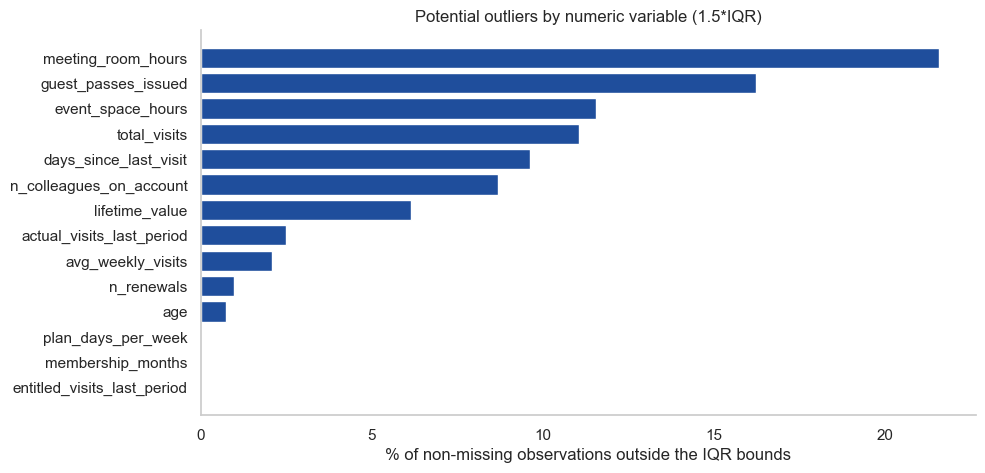

In [30]:
outlier_pct = iqr_table["% outliers"].dropna().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(outlier_pct.index, outlier_pct.values, color=STATUS_COLORS["active"])
ax.set(xlabel="% of non-missing observations outside the IQR bounds",
       title="Potential outliers by numeric variable (1.5*IQR)")
ax.grid(False)
sns.despine()
plt.show()

#### Highly skewed distributions and zero concentration

The original-scale boxplots in Section 4.1 show that some boxes appear very small. This can happen when a few very high values stretch the horizontal axis, as with long right tails, or when a high proportion of observations is exactly zero.

To examine these distributions more clearly, we show log-transformed histograms and boxplots for `total_visits`, `avg_weekly_visits`, `meeting_room_hours`, `event_space_hours`, `guest_passes_issued` and `lifetime_value`. We use `np.log1p(x)`, equivalent to $\ln(1+x)$, so zeros can be included.

The logarithm compresses large values, but it does not eliminate potential outliers or resolve a concentration at zero. In particular, the boxes for `event_space_hours` and `guest_passes_issued` may remain reduced to a line because their quartiles coincide at zero. The following table also shows the zero percentages for the three optional services features.

In [31]:
# The service-usage features have many zeros, so we describe them separately
zero_heavy_features = ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]
usage_rows = []

for col in zero_heavy_features:
    values = df[col].dropna()
    usage_rows.append({"feature": col, 'count of zeros': (values==0).sum(), '% of zeros': (values==0).mean()*100})
display(pd.DataFrame(usage_rows).set_index("feature").round(2))

,count of zeros,% of zeros
feature,,
meeting_room_hours,9738,67.40
event_space_hours,13121,88.46
guest_passes_issued,12266,83.78


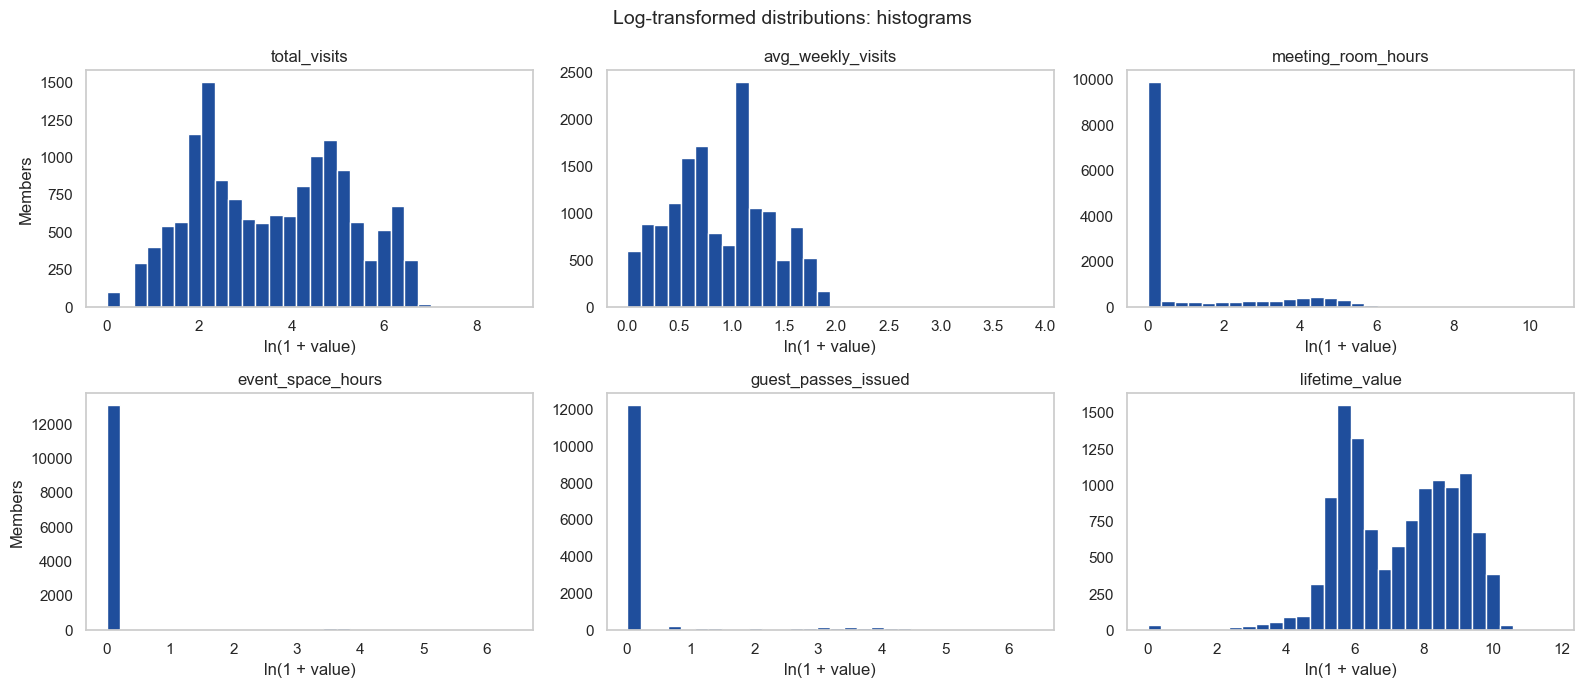

In [32]:
log_features = ["total_visits", "avg_weekly_visits", "meeting_room_hours",
                "event_space_hours", "guest_passes_issued", "lifetime_value"]

fig, axes = plt.subplots(2, 3, figsize=(16, 7))

for ax, col in zip(axes.flatten(), log_features):
    values = df[col].dropna()
    values = values[values >= 0]
    ax.hist(np.log1p(values), bins=30, color=STATUS_COLORS["active"])
    ax.set_title(col)
    ax.set_xlabel("ln(1 + value)")
    ax.grid(False)

axes[0, 0].set_ylabel("Members")
axes[1, 0].set_ylabel("Members")
fig.suptitle("Log-transformed distributions: histograms", fontsize=14)
fig.tight_layout()
plt.show()

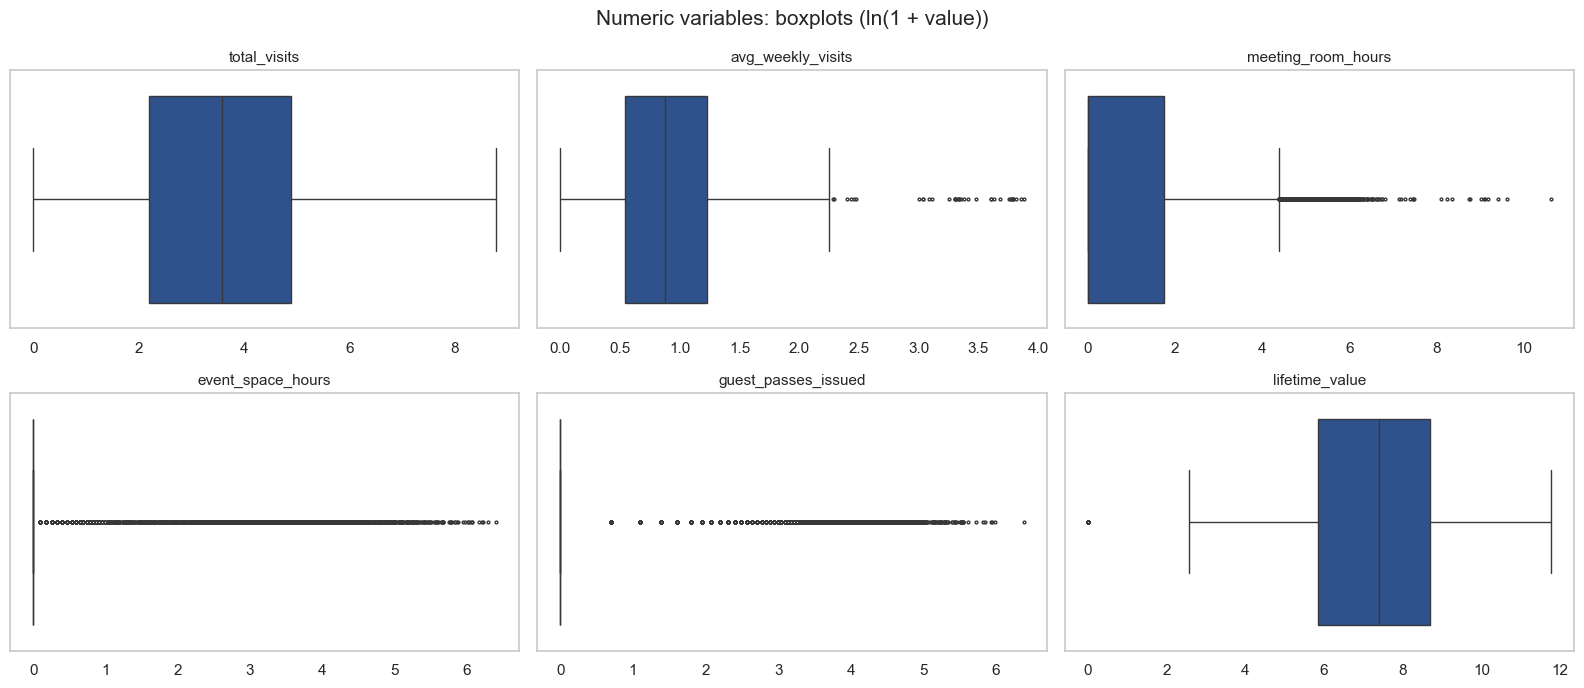

In [33]:
log_features = ["total_visits", "avg_weekly_visits", "meeting_room_hours",
                "event_space_hours", "guest_passes_issued", "lifetime_value"]

fig, axes = plt.subplots(2, 3, figsize=(16, 7))

for ax, col in zip(axes.flatten(), log_features):
    values = df[col].dropna()
    values = values[values >= 0]
    sns.boxplot(x=np.log1p(values), ax=ax, color=STATUS_COLORS["active"], fliersize=2)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="x")
    ax.grid(False)

fig.suptitle("Numeric variables: boxplots (ln(1 + value))", fontsize=15)
fig.tight_layout()
plt.show()

The logarithmic transformation helps visualize some distributions due to the compression of high values, especially `total_visits`, `avg_weekly_visits`, `meeting_room_hours` and `lifetime_value`. However, high values stay visible, so the transformation does not get rid of outliers.

The boxplots of `event_space_hours` and `guest_passes_issued` still stay compressed at zero since these services are not used by the majority of members. This proves that the distributions are mostly concentrated at zero values and not at high values.

In general, these findings imply that the variables should be preprocessed differently prior to clustering. First, it is important to distinguish high values from errors, but also to keep the information of those members who do not use some of the services.

#### Looking at some outliers

In [34]:
above_allowance = df["actual_visits_last_period"] > df["entitled_visits_last_period"] # visits above the allowance in the same period
print(f"actual_visits_last_period above entitled_visits_last_period: {above_allowance.sum()}")
print(f"  with an entitlement of 0: {(above_allowance & (df['entitled_visits_last_period'] == 0)).sum()}")
print(f"  with invalid plan days in the file (0 or 9): {(above_allowance & df['flag_plan_days_invalid']).sum()}")

top_member = df.loc[df["lifetime_value"].idxmax()] # Highest lifetime_value and high values in very short memberships
print(f"\nhighest lifetime_value: {top_member['lifetime_value']:.0f} EUR, with {top_member['meeting_room_hours']:.0f} meeting-room hours")
print(f"lifetime_value above 5000 EUR with under 1 month of membership: {((df['lifetime_value'] > 5000) & (df['membership_months'] < 1)).sum()}")

actual_visits_last_period above entitled_visits_last_period: 8
  with an entitlement of 0: 8
  with invalid plan days in the file (0 or 9): 8

highest lifetime_value: 128432 EUR, with 8928 meeting-room hours
lifetime_value above 5000 EUR with under 1 month of membership: 4


The boxplots in Section 4.1 use the cleaned data: the `lifetime_value` scale errors are already divided by 100, while the suspect visits and hours are flagged but not changed. Nothing is removed here (how we treat outliers is a decision for Deliverable 2)

- `lifetime_value`: the highest value is 128432 EUR, from a member who also has 8928 meeting-room hours. 4 members with under 1 month of membership have values above 5000 EUR, the scale-error rule does not check them because it starts at 1 month.
- `meeting_room_hours`: some values are implausible, up to 41220 hours and are left for Deliverable 2.
- `total_visits` and `avg_weekly_visits`: the largest values look about 10 times too high and are flagged in Section 3.4.
- `guest_passes_issued`: the maximum is 589 passes, from a member with 68 event-space hours over almost two years. A few large events could explain it, so we cannot rule it out.
- `actual_visits_last_period` is above `entitled_visits_last_period` in 8 rows. In all of them the entitlement is 0 and the plan days in the file were invalid (0 or 9).
- `meeting_room_hours`, `event_space_hours` and `guest_passes_issued` are mostly zeros, so many of the members who use these services look like outliers. That separates users from non-users and it should not be read as an error.
- `days_since_last_visit` measures different things: up to the end date for ended members and up to the reference date for active members, so it should not be compared directly between the two groups.

The other long upper tails may be useful for segmentation, because they show **who uses the services most**, **who renews** and **who spends most**.

### 4.3 What drives `lifetime_value`
The dataset has no price column, but the data suggests what each plan costs. Members with no add-ons should pay only for the plan, so for them `lifetime_value / membership_months` should be close to the plan price. We use members with at least 3 months, to avoid very short memberships and exclude the flagged scale errors.

In [35]:
use_cols = [c for c in df.columns if c.startswith("uses_")]
df["number_of_addons_used"] = df[use_cols].sum(axis=1)
# Estimation of plan prices using members with sufficient duration and no flagged lifetime_value scale error
valid = (df["lifetime_value"] > 0) & (df["membership_months"] >= 3) & df["plan_tier"].notna() & ~df["flag_ltv_scale_error"]
monthly = df["lifetime_value"]/df["membership_months"]

no_addons = df[valid & (df["number_of_addons_used"]==0)]
base_table = monthly[no_addons.index].groupby(no_addons["plan_tier"]).agg(["count", "mean", "std", "min", "max"]).reindex(TIER_ORDER).round(2)
base_price = base_table["mean"].round(-1)
display(base_table)

,count,mean,std,min,max
plan_tier,,,,,
hot_desk,337,119.96,0.30,118.89,121.02
flex,295,179.94,0.32,178.56,180.69
dedicated_desk,81,349.76,0.21,349.09,350.00
full_time,112,279.86,0.18,279.47,280.47
private_office,2,649.74,0.08,649.69,649.79


Members with no add-ons pay almost exactly the same per month within each plan: `hot_desk` ranges only from 118.89 to 121.02, for example. We round these values to plan prices of 120, 180, 350, 280 and 650 EUR. These are a reading of the data, not documented prices and the `private_office` price comes from only 2 members.

So `lifetime_value` depends mostly on the plan and on how long the member stays: its Spearman correlation with `membership_months` is 0.95 (Section 4.9). It should not be read as independent evidence alongside those columns.

### 4.4 Plans in the guideline order
The guidelines give the order of plans as `hot_desk` < `flex` < `dedicated_desk` < `full_time` < `private_office`. The table shows them in that order, so the metrics can be compared with it. Monthly revenue excludes zeros, missing values and flagged scale errors.

In [36]:
base = df[(df["lifetime_value"] > 0) & (df["membership_months"] >= 1) & df["plan_tier"].notna() & ~df["flag_ltv_scale_error"]]
plan_table = pd.DataFrame({
    "days per week": df.groupby("plan_tier")["plan_days_per_week"].median(),
    "base price (estimated)": base_price,
    "monthly revenue, mean": (base["lifetime_value"] / base["membership_months"]).groupby(base["plan_tier"]).mean().round(0),
    "monthly revenue, median": (base["lifetime_value"] / base["membership_months"]).groupby(base["plan_tier"]).median().round(0),
    "lifetime_value, median": base.groupby("plan_tier")["lifetime_value"].median().round(0),
    "membership months, median": df.groupby("plan_tier")["membership_months"].median().round(1),
    "renewals, median": df.groupby("plan_tier")["n_renewals"].median(),
    "weekly visits, median": df.groupby("plan_tier")["avg_weekly_visits"].median().round(2),
    "% active": df.groupby("plan_tier")["is_active"].mean().mul(100).round(1),
}).reindex(TIER_ORDER)
display(plan_table.T)

known = df[df["lifetime_value"] > 0]
share = pd.DataFrame({
    "% of members": df["plan_tier"].value_counts(normalize=True).mul(100),
    "% of known revenue": known.groupby("plan_tier")["lifetime_value"].sum() / known["lifetime_value"].sum() * 100,
}).reindex(TIER_ORDER).round(1)
display(share)

plan_tier,hot_desk,flex,dedicated_desk,full_time,private_office
days per week,2.00,3.00,5.00,5.00,7.00
base price (estimated),120.00,180.00,350.00,280.00,650.00
"monthly revenue, mean",169.00,234.00,420.00,349.00,722.00
"monthly revenue, median",132.00,205.00,407.00,313.00,701.00
"lifetime_value, median",366.00,2050.00,11117.00,6099.00,21739.00
"membership months, median",2.60,8.60,26.60,17.10,29.70
"renewals, median",0.00,0.00,2.00,1.00,2.00
"weekly visits, median",0.96,1.89,3.86,1.62,1.04
% active,13.40,20.50,57.00,38.00,46.40


,% of members,% of known revenue
plan_tier,,
hot_desk,33.9,11.1
flex,35.4,22.0
dedicated_desk,10.1,25.2
full_time,15.9,21.4
private_office,4.6,20.4


Although the guidelines order the plans as `hot_desk` < `flex` < `dedicated_desk` < `full_time` < `private_office`, ordering them by estimated monthly revenue gives `hot_desk` < `flex` < `full_time` < `dedicated_desk` < `private_office`.

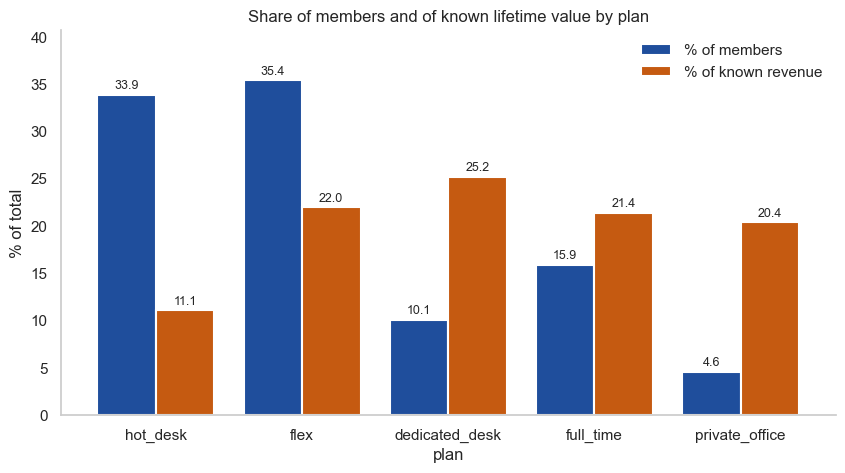

In [37]:
SHARE_COLORS = {"% of members": "#1F4E9C", "% of known revenue": "#C55A11"}

fig, ax = plt.subplots(figsize=(10, 5))
share.plot.bar(ax=ax, width=0.8, color=SHARE_COLORS, edgecolor="white", linewidth=1.5, rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=9)
ax.set(xlabel="plan", ylabel="% of total", title="Share of members and of known lifetime value by plan", ylim=(0, share.values.max() * 1.15))
ax.legend(frameon=False)
ax.grid(False)
sns.despine()
plt.show()

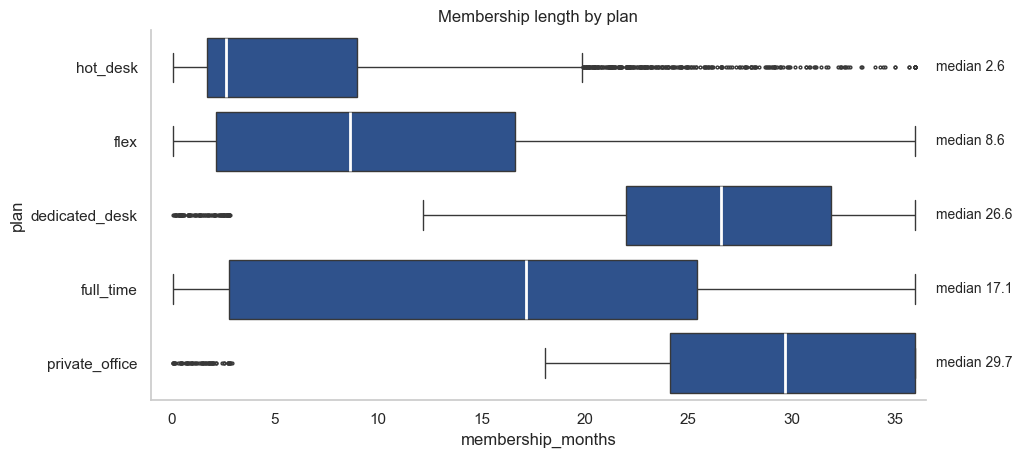

In [38]:
medians = df.groupby("plan_tier")["membership_months"].median().reindex(TIER_ORDER)

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.boxplot(data=df, x="membership_months", y="plan_tier", order=TIER_ORDER, color=STATUS_COLORS["active"],
            fliersize=2, medianprops={"color": "white", "linewidth": 2}, ax=ax)
for position, value in enumerate(medians):
    ax.text(37, position, f"median {value:.1f}", va="center", fontsize=10)
ax.set(xlabel="membership_months", ylabel="plan", title="Membership length by plan", xlim=(-1, 36.5))
ax.grid(False)
sns.despine()
plt.show()

#### Remarkable conclusion
Although most members are hot_desk or the flex plans (69.3%), most of the known lifetime value comes from the other plans, dedicated_desk, full_time and private_office (66.9%). Members on dedicated desks and private offices also stay longer. This may mean ACDC should invest more in these two plans, as they bring more revenue. That increased revenue is justified by the members staying more time and also the plans being more expensive.

### 4.5 Active and ended members
For active members, tenure (membership duration) is measured from their start date up to the reference date, since their memberships have not ended. As the two groups joined at different times, we should be careful when comparing them.

In [39]:
display(df.groupby('status')[['membership_months', 'total_visits', 'lifetime_value', 'actual_visits_last_period', 'n_renewals']].median().round(2))

,membership_months,total_visits,lifetime_value,actual_visits_last_period,n_renewals
status,,,,,
active,19.06,17.0,4356.86,4.0,1.0
ended,8.11,59.0,1413.51,13.0,0.0


When comparing members by year of start of membership, we should keep in mind that those who joined more recently have had less time to leave, which can affect the percentage of ended memberships.

,members,% ended,"median membership duration, months"
membership_start,,,
2021,7313,79.5,19.2
2022,4274,82.9,9.1
2023,3253,50.9,1.8


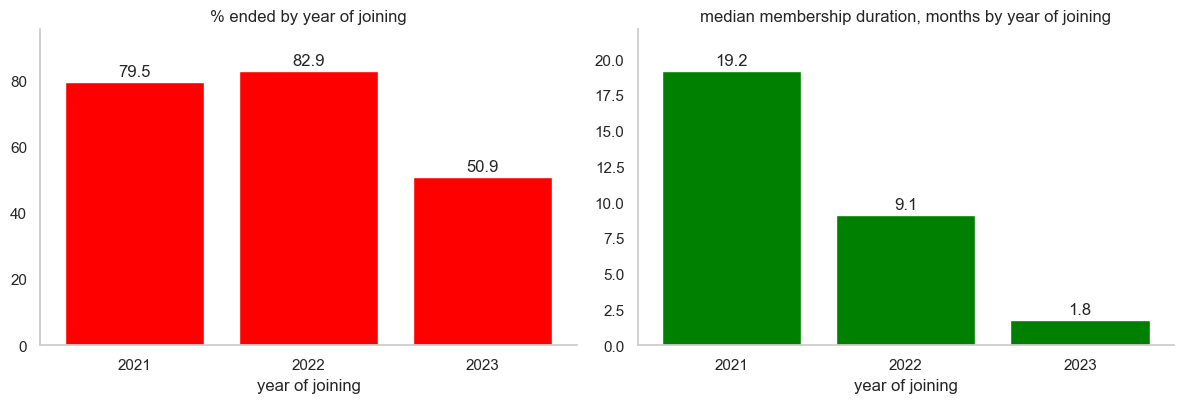

In [40]:
start_year = df["membership_start"].dt.year
cohort = pd.DataFrame({
    'members': start_year.value_counts().sort_index(),
    '% ended': ((~df["is_active"]).groupby(start_year).mean()*100).round(1),
    'median membership duration, months': df.groupby(start_year)['membership_months'].median().round(1),
})
display(cohort)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, column, color in zip(axes, ['% ended', 'median membership duration, months'], ["red", "green"]):
    bars = ax.bar(cohort.index.astype(str), cohort[column], color=color)
    ax.bar_label(bars, fmt="%.1f", padding=2)
    ax.set(title=f"{column} by year of joining", xlabel="year of joining", ylim=(0, cohort[column].max() * 1.15))
    ax.grid(False)
sns.despine()
plt.tight_layout()
plt.show()

The comparison between active and ended members shows differences in tenure, visits, lifetime value and renewals. Members who joined more recently have had less time to end their memberships, as it tends to happen in reality.

For clustering, these variables could help identify different patterns of customer engagement and loyalty, taking into account membership tenure, since members who have been with ACDC longer have had more time to accumulate visits, renewals and lifetime value.

### 4.6 Use of the plan allowance
`plan_usage_rate` is `actual_visits_last_period / entitled_visits_last_period`. It should be read with care for very recent members: someone who joined a few days ago has an allowance of about 1 visit, so not having come yet gives 0%, which is not the same as not using the plan.

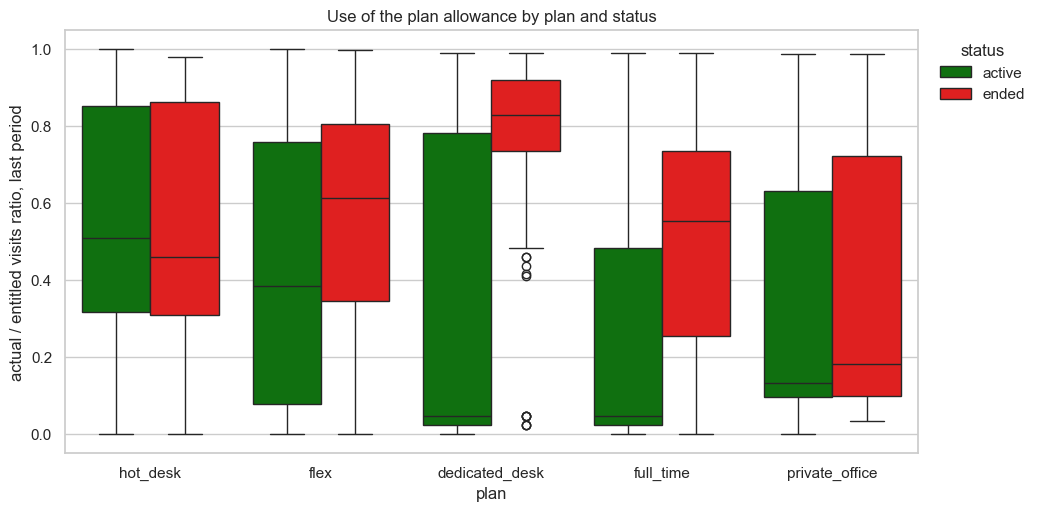

status,active,ended
plan_tier,,
hot_desk,0.51,0.46
flex,0.38,0.61
dedicated_desk,0.05,0.83
full_time,0.05,0.55
private_office,0.13,0.18


In [41]:
df["plan_usage_rate"] = (df["actual_visits_last_period"]/df["entitled_visits_last_period"]).where(df["entitled_visits_last_period"] > 0) #the ratio is undefined when a member has no entitled visits
util = df[['plan_usage_rate', 'plan_tier', 'status']].dropna()
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=util, x="plan_tier", y="plan_usage_rate", hue="status", order=TIER_ORDER, hue_order=["active", "ended"], palette={"active": "green", "ended": "red"}, ax=ax)
ax.set(xlabel="plan", ylabel="actual / entitled visits ratio, last period", title="Use of the plan allowance by plan and status")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()
display(df.groupby(["plan_tier", "status"])["plan_usage_rate"].median().unstack().reindex(TIER_ORDER).round(2))

In [42]:
df["days_since_last_visit_active"] = (reference_date - df["last_badge_swipe"]).dt.days.where(df["is_active"])
#restricting the low-usage features analysis to active members with a valid usage ratio
active_valid = df["is_active"] & df["plan_usage_rate"].notna()
low_use = active_valid & (df["plan_usage_rate"] < 0.10)
low_table = pd.DataFrame({
    "active members": active_valid.groupby(df["plan_tier"]).sum(),
    "below 10% of allowance": low_use.groupby(df["plan_tier"]).sum(),
    "median days since last visit": df[low_use].groupby("plan_tier")["days_since_last_visit_active"].median(),
    "median membership duration, months": df[low_use].groupby("plan_tier")["membership_months"].median().round(1),
}).reindex(TIER_ORDER)
low_table["% below 10%"] = (low_table["below 10% of allowance"] / low_table["active members"] * 100).round(1)
display(low_table)

,active members,below 10% of allowance,median days since last visit,"median membership duration, months",% below 10%
plan_tier,,,,,
hot_desk,673,44,4.0,0.1,6.5
flex,1076,362,188.0,26.1,33.6
dedicated_desk,855,514,187.5,25.9,60.1
full_time,897,564,198.0,25.6,62.9
private_office,319,99,11.0,36.0,31.0


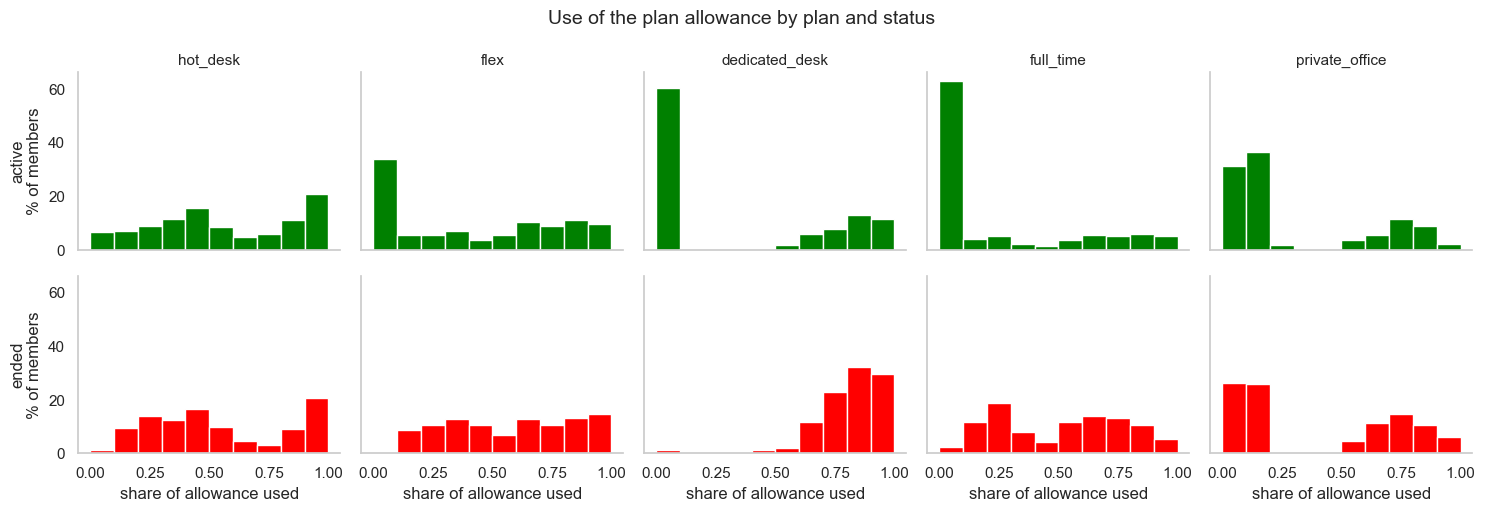

active, under 10% of allowance: 60.1% | weekly visits 0.17 | days since last visit 188 | shortest membership 12.2 months
active, at least 50% of allowance: 39.4% | weekly visits 4.16 | days since last visit 3 | shortest membership 0.1 months
ended: under 10% of allowance 1.1% | weekly visits 4.19


In [43]:
usage = df[df["plan_usage_rate"].notna() & df["plan_tier"].notna()]

fig, axes = plt.subplots(2, 5, figsize=(15, 5.2), sharex=True, sharey=True)
for col, plan in enumerate(TIER_ORDER):
    for row, status in enumerate(["active", "ended"]):
        values = usage.loc[(usage["plan_tier"] == plan) & (usage["status"] == status), "plan_usage_rate"]
        ax = axes[row, col]
        ax.hist(values, bins=np.arange(0, 1.01, 0.1), weights=np.full(len(values), 100 / len(values)),
                color={"active": "green", "ended": "red"}[status], edgecolor="white")
        ax.grid(False)
        if row == 0:
            ax.set_title(plan, fontsize=11)
        else:
            ax.set_xlabel("share of allowance used")
        if col == 0:
            ax.set_ylabel(f"{status}\n% of members")
fig.suptitle("Use of the plan allowance by plan and status", fontsize=14)
sns.despine()
fig.tight_layout()
plt.show()

dedicated = usage[usage["plan_tier"] == "dedicated_desk"]
active = dedicated[dedicated["is_active"]]
for name, group in [("under 10% of allowance", active[active["plan_usage_rate"] < 0.1]), ("at least 50% of allowance", active[active["plan_usage_rate"] >= 0.5])]:
    print(f"active, {name}: {len(group) / len(active):.1%} | weekly visits {group['avg_weekly_visits'].median():.2f} | "
          f"days since last visit {group['days_since_last_visit'].median():.0f} | shortest membership {group['membership_months'].min():.1f} months")
ended = dedicated[~dedicated["is_active"]]
print(f"ended: under 10% of allowance {(ended['plan_usage_rate'] < 0.1).mean():.1%} | weekly visits {ended['avg_weekly_visits'].median():.2f}")

Many active members have almost stopped coming. On dedicated desks, 60.1% of active members use under 10% of their allowance and their last visit was about 188 days ago. The other 39.4% use at least 50% and come as often as the members who left (about 4 visits per week). Almost no ended member shows this low use (1.1%).

### 4.7 Behaviour inside each plan
Comparing members within a plan removes the part of the difference that only reflects what they bought. Two limits apply when reading this table: for active members, tenure (membership duration) is measured only up to the reference date, `days_since_last_visit` counts to the end date for ended members but to the reference date for active members, so that column is not comparable across status.

In [44]:
monthly_revenue = (df["lifetime_value"] / df["membership_months"]).where((df["lifetime_value"] > 0) & (df["membership_months"] >= 1))
behaviour_profile = (
    df.assign(monthly_revenue=monthly_revenue).groupby(["plan_tier", "status"])
    .agg(members=("member_id", "size"),
         monthly_revenue=("monthly_revenue", "median"),
         avg_weekly_visits=("avg_weekly_visits", "median"),
         plan_usage_rate=("plan_usage_rate", "median"),
         membership_months=("membership_months", "median"),
         number_of_addons_used=("number_of_addons_used", "median"),
         days_since_last_visit=("days_since_last_visit", "median"))
    .reindex(TIER_ORDER, level=0).round(2))
display(behaviour_profile)

members  monthly_revenue  avg_weekly_visits  \
plan_tier      status                                                
hot_desk       active      674           134.51               1.02   
               ended      4356           131.62               0.95   
flex           active     1076           197.14               1.16   
               ended      4184           205.20               1.94   
dedicated_desk active      855           377.77               0.30   
               ended       645           430.76               4.19   
full_time      active      899           304.72               0.28   
               ended      1464           319.70               3.07   
private_office active      319           699.68               0.93   
               ended       368           706.51               1.25   

                       plan_usage_rate  membership_months  \
plan_tier      status                                       
hot_desk       active             0.51               1.28   
               ended              0.46               2.83   
flex           active             0.38               2.60   
               ended              0.61               9.13   
dedicated_desk active             0.05              26.35   
               ended              0.83              26.87   
full_time      active             0.05              23.75   
               ended              0.55              13.82   
private_office active             0.13              35.98   
               ended              0.18              28.30   

                       number_of_addons_used  days_since_last_visit  
plan_tier      status                                                
hot_desk       active                    1.0                    9.0  
               ended                     1.0                   19.0  
flex           active                    1.0                   16.0  
               ended                     1.0                   10.0  
dedicated_desk active                    2.0                  139.0  
               ended                     4.0                    3.0  
full_time      active                    2.0                  146.0  
               ended                     2.0                    8.0  
private_office active                    3.0                    8.0  
               ended                     3.0                    6.0

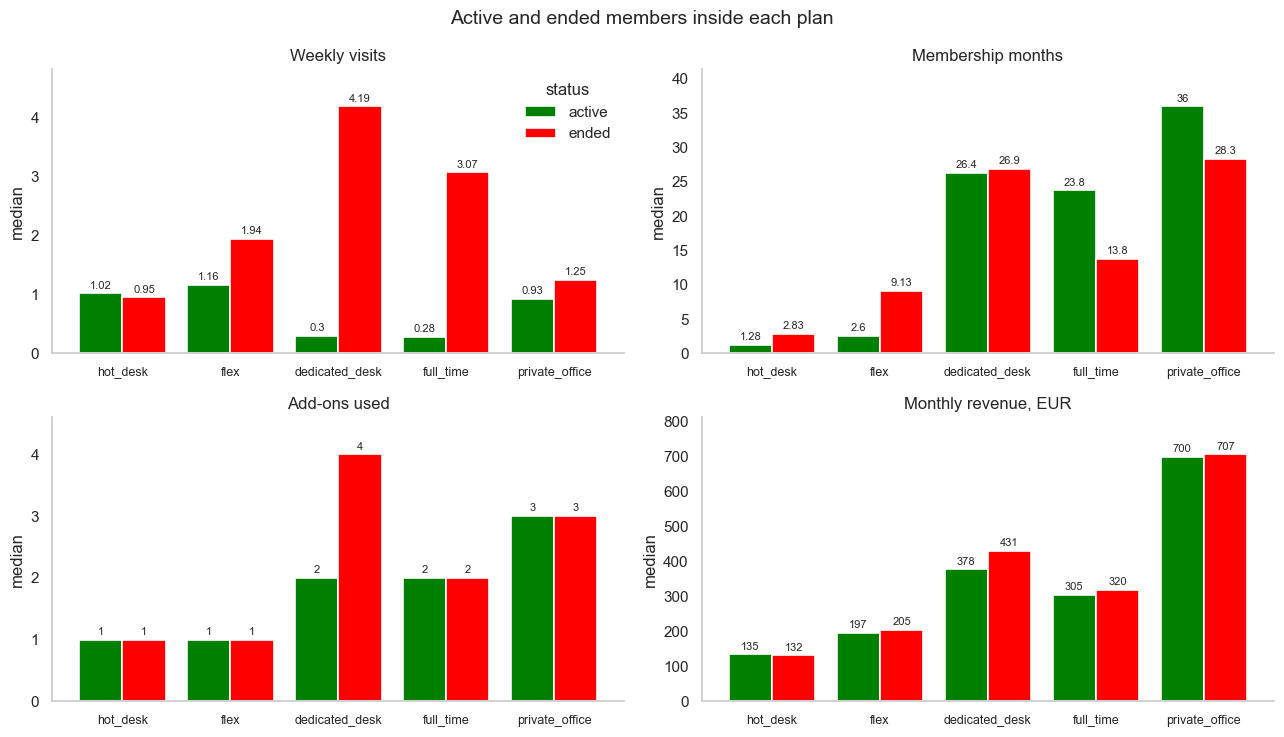

In [45]:
status_colors_gr = {"active": "green", "ended": "red"}

panels = {"avg_weekly_visits": "Weekly visits", "membership_months": "Membership months",
          "number_of_addons_used": "Add-ons used", "monthly_revenue": "Monthly revenue, EUR"}

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, (column, title) in zip(axes.flatten(), panels.items()):
    table = behaviour_profile[column].unstack().reindex(TIER_ORDER)[["active", "ended"]]
    table.plot.bar(ax=ax, width=0.8, color=status_colors_gr, edgecolor="white", linewidth=1.2, rot=0, legend=False)
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.3g", padding=2, fontsize=8)
    ax.set(title=title, xlabel="", ylabel="median", ylim=(0, table.values.max() * 1.15))
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(False)
axes[0, 0].legend(title="status", frameon=False)
fig.suptitle("Active and ended members inside each plan", fontsize=14)
sns.despine()
fig.tight_layout()
plt.show()

Within each plan, active and ended members bring similar monthly revenue. The low medians of active members on dedicated desks and full-time plans come from the low-use group in Section 4.6, so they do not describe a typical member.

### 4.8 Country, plan tier and lifetime value

To compare countries within each plan, we look at how the median `lifetime_value` in each country differs from the overall median of that plan. The heatmap shows this difference as a percentage, while each cell also shows the number of members with a recorded lifetime value. We use the median rather than the mean because `lifetime_value` has a strongly skewed distribution, with some members generating much higher values than others. These extreme values could pull the mean upwards and make a country-plan group look more valuable than is typical for its members. The median is less affected by these extremes, giving us a more representative comparison. The counts help us identify combinations with few observations.

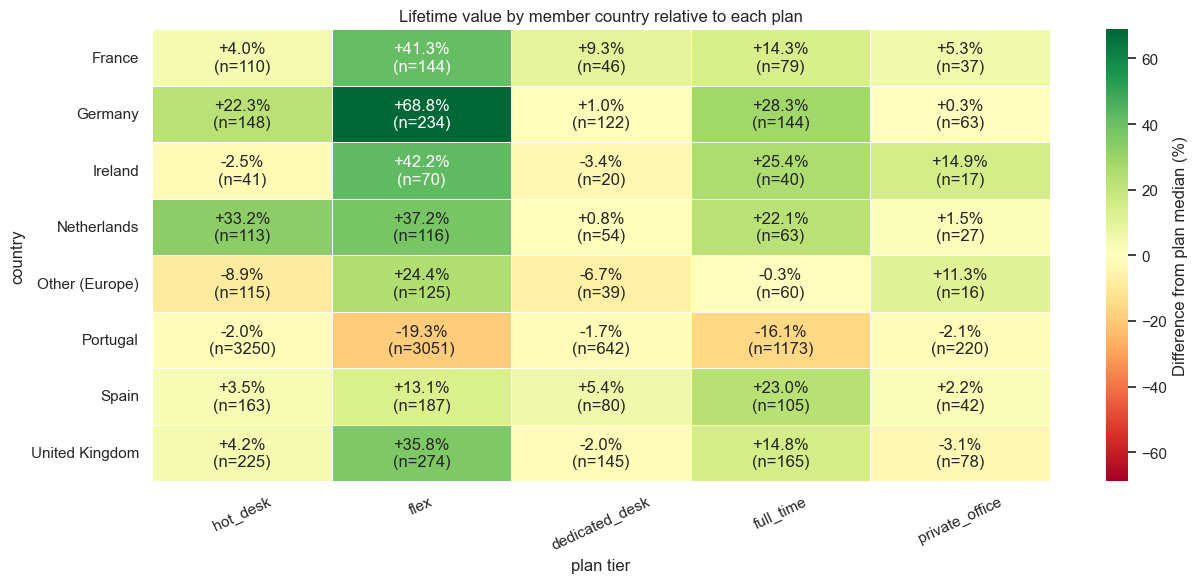

In [46]:
country_plan = df.dropna(subset=["country", "plan_tier", "lifetime_value"])
median_ltv = country_plan.pivot_table(
    index="country", columns="plan_tier", values="lifetime_value", aggfunc="median"
).reindex(columns=TIER_ORDER)
member_counts = country_plan.pivot_table(
    index="country", columns="plan_tier", values="lifetime_value", aggfunc="count"
).reindex(index=median_ltv.index, columns=TIER_ORDER).fillna(0).astype(int)

# Compare countries within each plan, relative to that plan median lifetime value:
plan_medians = df.groupby("plan_tier")["lifetime_value"].median()

# Divide by each plan's overall median to make countries comparable within a plan:
relative_ltv = ((median_ltv.div(plan_medians, axis=1) - 1) * 100).reindex(columns=TIER_ORDER)

labels_relative = relative_ltv.copy().astype(object)
for country in relative_ltv.index:
    for plan in relative_ltv.columns:
        value = relative_ltv.loc[country, plan]
        n = member_counts.loc[country, plan]
        labels_relative.loc[country, plan] = f"{value:+.1f}%\n(n={n})" if pd.notna(value) else ""

limit = np.nanmax(np.abs(relative_ltv.to_numpy()))

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(relative_ltv, annot=labels_relative, fmt="", cmap="RdYlGn",
            vmin=-limit, vmax=limit, center=0, linewidths=0.5,
            cbar_kws={"label": "Difference from plan median (%)"}, ax=ax)
ax.set(title="Lifetime value by member country relative to each plan",
       xlabel="plan tier", ylabel="country")
ax.tick_params(axis="x", labelrotation=25)
ax.tick_params(axis="y", labelrotation=0)
plt.tight_layout()
plt.show()

The clearest differences appear in the `flex` plan. Members from Germany stand out with a median `lifetime_value` 68.8% above the overall plan median, followed by Ireland (+42.2%), France (+41.3%) and the Netherlands (+37.2%). The Netherlands also stands out in `hot_desk` (+33.2%), while Germany is above the plan median in `full_time` (+28.3%).

Portuguese members show some of the most evident negative differences, especially in `flex` (-19.3%) and `full_time` (-16.1%). These groups have a large number of members (3051 and 1173, respectively), so their medians are less likely to change significantly due to a few individual observations. For example, Germany with 234 members stand out positively in the `flex` plan (+68.8%), however it's still useful to mention these differences in values.

We can also say that plan prices essentially do not change in `dedicated_desk` and in part in `private_office`: members pay almost the same in every country.

### 4.9 Relationships between variables

Before looking at the correlations matrix between numeric variables, we find interesting 3 relationships that may help us better understand customer behaviour and identify useful information for clustering.

We start by comparing `total_visits` with `lifetime_value` to see if members who visit more frequently also generate more revenue; `membership_months` with `total_visits` to understand how membership duration affects the number of visits; `meeting_room_hours` with `lifetime_value` to find if meeting room usage is associated with higher customer lifetime value.

For each relationship, we compare the linear and log-log scales, because as the linear scale shows the original values, the log-log scale makes it easier to observe patterns that may be hidden by extreme values.

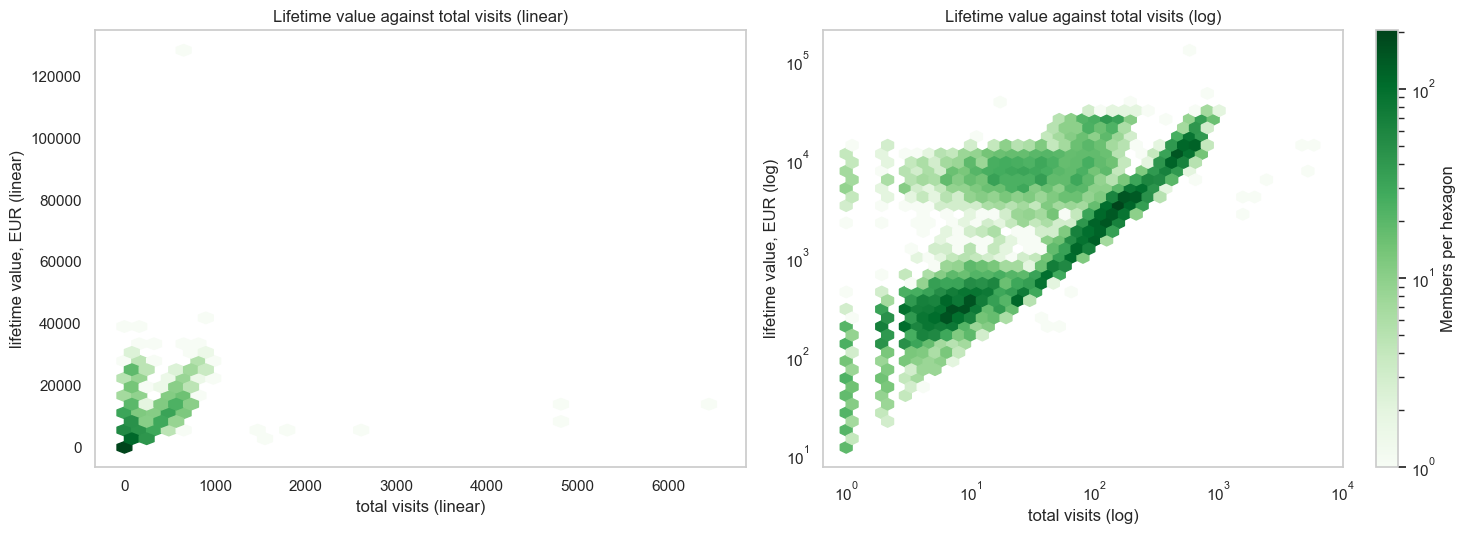

Spearman = 0.78
Pearson (original) = 0.57
Pearson (log-log) = 0.79


In [47]:
#total_visits and lifetime_value: linear vs log-log:

xy = df.loc[(df["total_visits"] > 0) & (df["lifetime_value"] > 0),
            ["total_visits", "lifetime_value"]]

fig,axes=plt.subplots(1, 2, figsize=(15, 5.5))

for ax, scale in zip(axes, ['linear', 'log']):
    hb = ax.hexbin(
        xy['total_visits'],
        xy['lifetime_value'],
        gridsize=40,
        xscale=scale,
        yscale=scale,
        bins="log",
        cmap="Greens"
    )

    ax.set(
        xlabel=f"total visits ({scale})",
        ylabel=f"lifetime value, EUR ({scale})",
        title=f"Lifetime value against total visits ({scale})"
    )
    ax.grid(False)
    if scale == "log":
        fig.colorbar(hb, ax=ax, label="Members per hexagon")

plt.tight_layout()
plt.show()

print(f"Spearman = {xy.corr(method='spearman').iloc[0, 1]:.2f}")
print(f"Pearson (original) = {xy.corr().iloc[0, 1]:.2f}")
print(f"Pearson (log-log) = {np.log(xy).corr().iloc[0, 1]:.2f}")

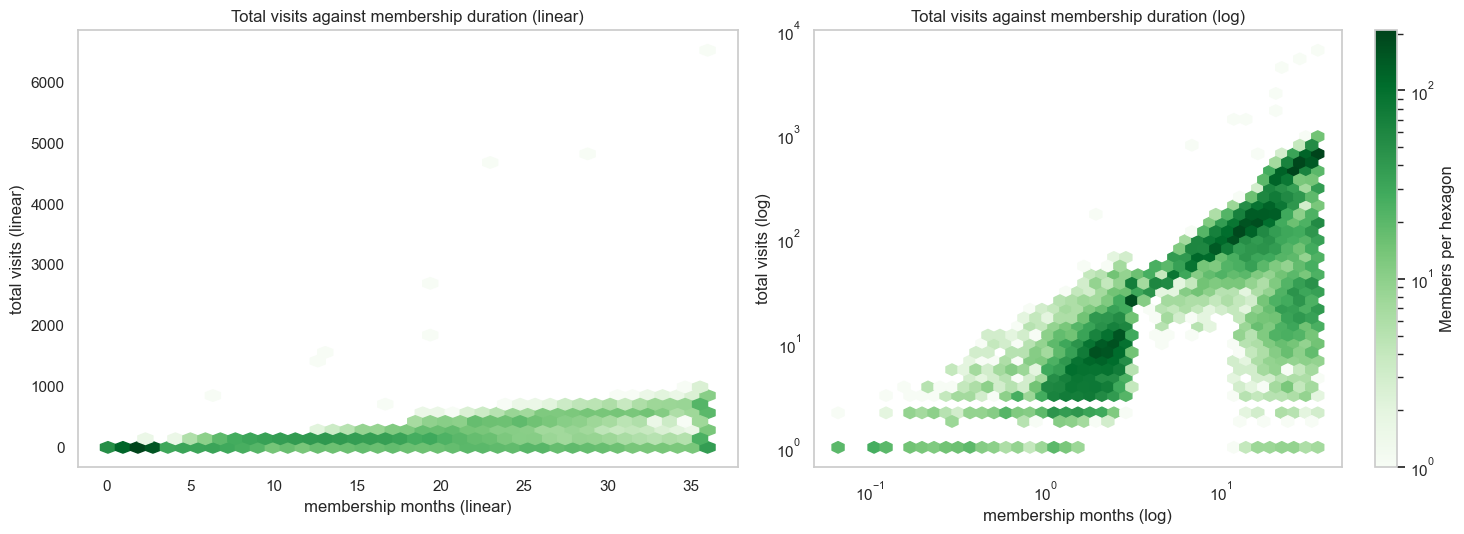

Spearman = 0.76
Pearson (original) = 0.59
Pearson (log-log) = 0.80
Rows excluded from log-log plot (zeros): 103


In [48]:
#membership_months and total_visits: linear vs log-log:

xy_membership = df[["membership_months", "total_visits"]].dropna()
xy_membership = xy_membership[(xy_membership["membership_months"] >= 0) & (xy_membership["total_visits"] >= 0)]
# Logarithmic axes cannot include zero, so keep a positive-only subset for that plot.
xy_membership_positive = xy_membership[(xy_membership["membership_months"] > 0) & (xy_membership["total_visits"] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, scale in zip(axes, ["linear", "log"]):
    data = xy_membership if scale == "linear" else xy_membership_positive

    hb = ax.hexbin(
        data["membership_months"], data["total_visits"],
        gridsize=40, xscale=scale, yscale=scale,
        bins="log", cmap="Greens"
    )
    ax.set(
        xlabel=f"membership months ({scale})",
        ylabel=f"total visits ({scale})",
        title=f"Total visits against membership duration ({scale})"
    )
    ax.grid(False)
    if scale == "log":
        fig.colorbar(hb, ax=ax, label="Members per hexagon")

plt.tight_layout()
plt.show()

print(f"Spearman = {xy_membership.corr(method='spearman').iloc[0, 1]:.2f}")
print(f"Pearson (original) = {xy_membership.corr().iloc[0, 1]:.2f}")
print(f"Pearson (log-log) = {np.log(xy_membership_positive).corr().iloc[0, 1]:.2f}")
print(f"Rows excluded from log-log plot (zeros): {len(xy_membership) - len(xy_membership_positive)}")

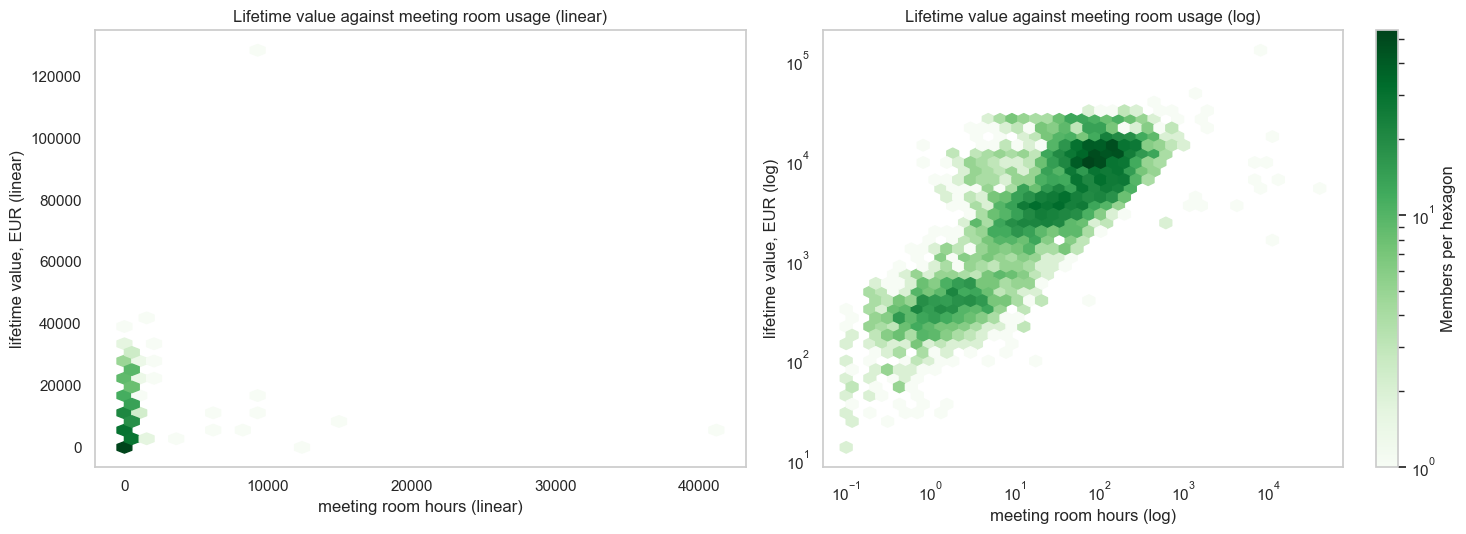

Spearman = 0.42
Pearson (original) = 0.11
Pearson (log-log) = 0.83
Rows excluded from log-log plot (zeros): 8011


In [49]:
#meeting_room_hours and lifetime_value: linear vs log-log:

xy_meeting = df[["meeting_room_hours", "lifetime_value"]].dropna()
xy_meeting = xy_meeting[(xy_meeting["meeting_room_hours"] >= 0) & (xy_meeting["lifetime_value"] >= 0)]

# Logarithmic axes cannot include zero
xy_meeting_positive = xy_meeting[(xy_meeting["meeting_room_hours"] > 0) & (xy_meeting["lifetime_value"] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, scale in zip(axes, ["linear", "log"]):
    data = xy_meeting if scale == "linear" else xy_meeting_positive

    hb = ax.hexbin(
        data["meeting_room_hours"], data["lifetime_value"],
        gridsize=40, xscale=scale, yscale=scale,
        bins="log", cmap="Greens"
    )
    ax.set(
        xlabel=f"meeting room hours ({scale})",
        ylabel=f"lifetime value, EUR ({scale})",
        title=f"Lifetime value against meeting room usage ({scale})"
    )
    ax.grid(False)
    if scale == "log":
        fig.colorbar(hb, ax=ax, label="Members per hexagon")

plt.tight_layout()
plt.show()

print(f"Spearman = {xy_meeting.corr(method='spearman').iloc[0, 1]:.2f}")
print(f"Pearson (original) = {xy_meeting.corr().iloc[0, 1]:.2f}")
print(f"Pearson (log-log) = {np.log(xy_meeting_positive).corr().iloc[0, 1]:.2f}")
print(f"Rows excluded from log-log plot (zeros): {len(xy_meeting) - len(xy_meeting_positive)}")

The 3 relationships above show that customer activity, membership duration and lifetime value are highly connected. Members who have been with ACDC longer had more time to increase visits, which may also contribute to higher lifetime value.

Meeting room usage show us that the large number of members with zero values usage makes this relationship harder to interpret, as we can observe in the graphic between linear `lifetime_value` and linear `meeting_room_hours`.

For clustering, these relationships are important because some variables may contain overlapping information. We should consider this when selecting features, so that membership duration or accumulated activity does not have too much influence on the resulting clusters.

#### Associations between numeric variables

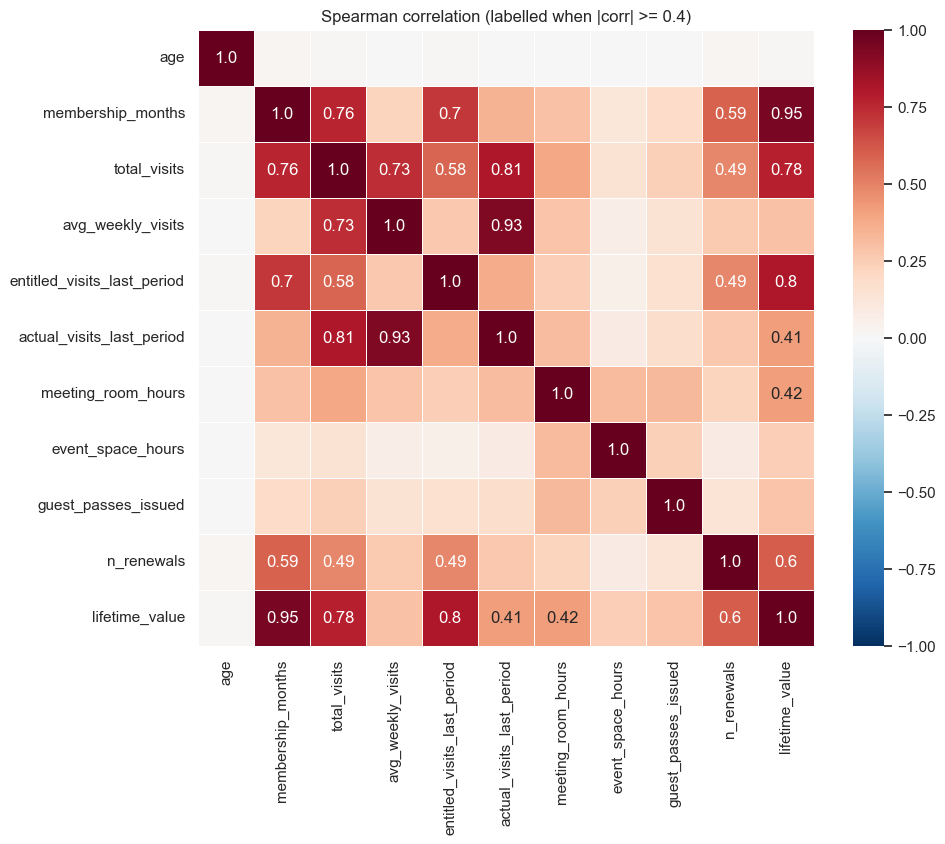

In [50]:
corr_features = ["age", "membership_months", "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
                 "actual_visits_last_period", "meeting_room_hours", "event_space_hours", "guest_passes_issued",
                 "n_renewals", "lifetime_value"]
corr = df[corr_features].corr(method="spearman")

# Show numbers only for correlations with an absolute value of at least 0.4 for a clean visualisation
annot = np.where(np.abs(corr.values) >= 0.4, corr.values.round(2).astype(str), "")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=annot, fmt="", vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, cmap="RdBu_r", ax=ax)
ax.set_title("Spearman correlation (labelled when |corr| >= 0.4)")
plt.show()

#### Associations between categorical and binary variables

We also examine relationships between categorical variables using **Cramér's V**, which ranges from 0 to 1 (perfect association). It does not indicate the direction of a relationship, unlike Pearson and Spearman correlations.

The matrix includes `plan_tier`, `gender`, `industry`, `country`, membership `status`, `is_team_account` and the `uses_...` service flags. Binary variables are included because they can reveal links between plans, member characteristics and service usage and we exclude id, data-cleaning flags and `is_active`, which is redundant with `status`.

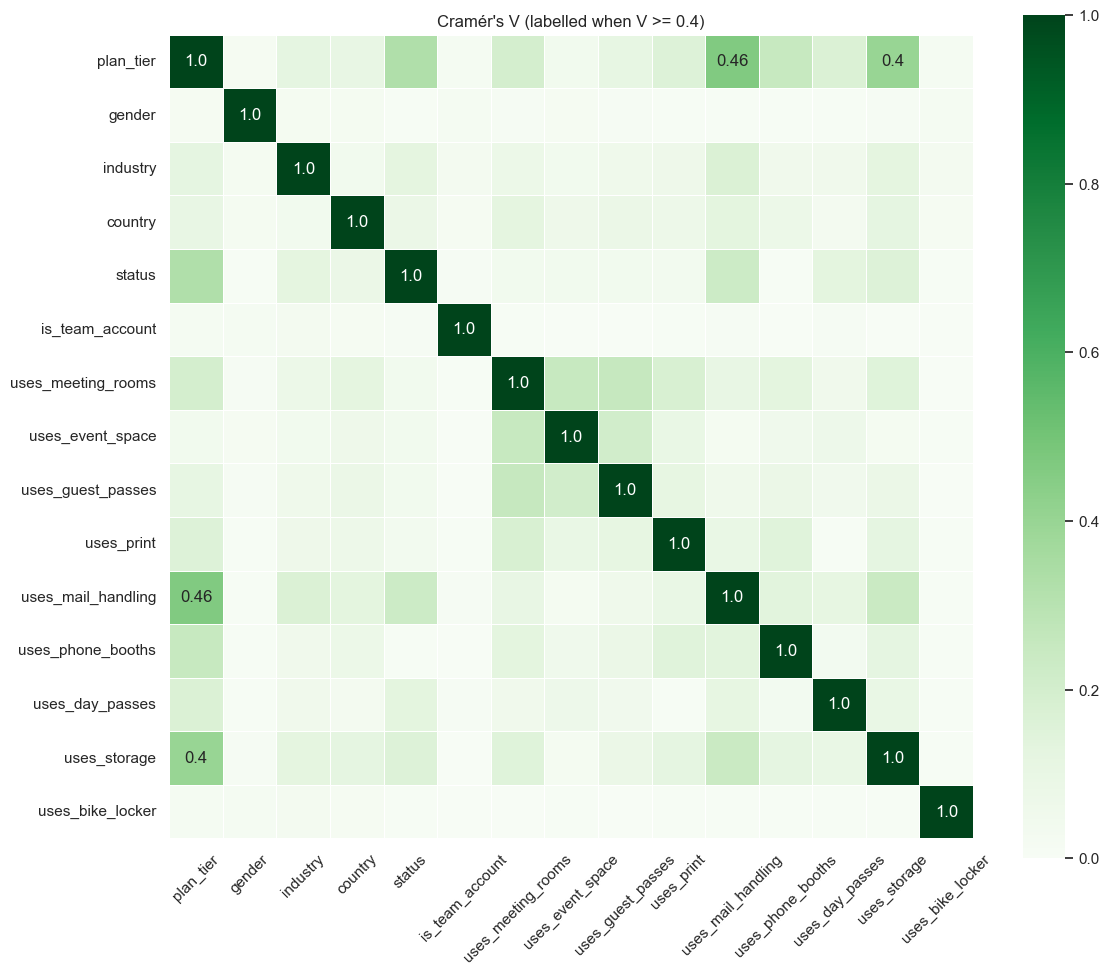

In [51]:
categorical_features = ordinal_features + nominal_features + ["status", "is_team_account"] + [c for c in df.columns if c.startswith("uses_")]

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return np.nan

    # Cramér's V scales the chi-square statistic by sample size and table dimensions.
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

cramers_matrix = pd.DataFrame(index=categorical_features, columns=categorical_features, dtype=float)

for col1 in categorical_features:
    for col2 in categorical_features:
        cramers_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])

annot = np.where(cramers_matrix.values >= 0.4, cramers_matrix.values.round(2).astype(str), "")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cramers_matrix, annot=annot, fmt="", vmin=0, vmax=1,
            cmap="Greens", square=True, linewidths=0.5, ax=ax)
ax.set_title("Cramér's V (labelled when V >= 0.4)")
ax.tick_params(axis="x", labelrotation=45)
ax.tick_params(axis="y", labelrotation=0)
plt.tight_layout()
plt.show()

The Spearman correlation matrix shows us several strong positive relationships between numeric variables. For example, `membership_months` and `lifetime_value` are highly correlated, suggesting that members who stay longer tend to generate more revenue. We also observe strong correlations between `avg_weekly_visits` and `actual_visits_last_period` and between `total_visits` and `membership_months`. These relationships suggest that some variables contain similar information.

In the Cramér's V matrix, there are fewer strong associations between categorical and binary variables. Most pairs show relatively weak associations, suggesting that these variables capture different aspects of the members and their use of services.

For clustering, these results are useful when selecting features. We should be careful about including several highly correlated numeric variables, as this could give certain aspects of customer behaviour too much weight. On the other hand, the weaker associations among categorical variables suggest that they may provide complementary information for segmentation.

## 5. Data Preparation: engineered features
Each feature must add something the source columns do not already say. The table defines them and the correlations below show how much they overlap with related columns.


In [52]:
df["monthly_value"] = df["lifetime_value"] / df["membership_months"]
# Encoding plans using their order:
df["plan_tier_ordinal"] = df["plan_tier"].map({tier: i + 1 for i, tier in enumerate(TIER_ORDER)})

feature_table = pd.DataFrame([
    ("membership_months", "(membership_end or reference date - membership_start) / DAYS_PER_MONTH", "Length of the relationship"),
    ("plan_usage_rate", "actual_visits_last_period / entitled_visits_last_period", "Use of the plan allowance"),
    ("number_of_addons_used", "number of 'uses_...' flags that are True", "Breadth of services used"),
    ("monthly_value", "lifetime_value / membership_months", "Monthly revenue, separated from duration"),
    ("days_since_last_visit_active", "reference date - last_badge_swipe, active members only", "Current inactivity"),
    ("plan_tier_ordinal", "guideline order, 1 to 5", "Encoding of the ordinal plan variable"),
], columns=["feature", "formula", "meaning"]).set_index("feature")
feature_table["missing"] = df[feature_table.index].isna().sum()
feature_table["median"] = df[feature_table.index].median().round(2)
display(feature_table)

,formula,meaning,missing,median
feature,,,,
membership_months,(membership_end or reference date - membership...,Length of the relationship,0,9.23
plan_usage_rate,actual_visits_last_period / entitled_visits_la...,Use of the plan allowance,10,0.52
number_of_addons_used,number of 'uses_...' flags that are True,Breadth of services used,0,1.00
monthly_value,lifetime_value / membership_months,"Monthly revenue, separated from duration",2697,205.00
days_since_last_visit_active,"reference date - last_badge_swipe, active memb...",Current inactivity,11017,19.00
plan_tier_ordinal,"guideline order, 1 to 5",Encoding of the ordinal plan variable,0,2.00


In [53]:
checks = [("membership_months", "n_renewals"), ("membership_months", "total_visits"), ("plan_usage_rate", "avg_weekly_visits"),
          ("plan_usage_rate", "actual_visits_last_period"), ("number_of_addons_used", "lifetime_value"),
          ("monthly_value", "plan_tier_ordinal"), ("monthly_value", "number_of_addons_used"), ("monthly_value", "lifetime_value"),
          ("days_since_last_visit_active", "plan_usage_rate")]
# Calculate Spearman correlation for each chosen pair of engineered and existing features.
display(pd.DataFrame([{"feature": a, "compared with": b, "spearman": round(df[[a, b]].corr(method="spearman").iloc[0, 1], 2)} for a, b in checks]))

,feature,compared with,spearman
0,membership_months,n_renewals,0.59
1,membership_months,total_visits,0.76
2,plan_usage_rate,avg_weekly_visits,0.84
3,plan_usage_rate,actual_visits_last_period,0.84
4,number_of_addons_used,lifetime_value,0.53
5,monthly_value,plan_tier_ordinal,0.80
6,monthly_value,number_of_addons_used,0.68
7,monthly_value,lifetime_value,0.74
8,days_since_last_visit_active,plan_usage_rate,-0.79


The engineered features give us a clearer picture of each member beyond the original columns. For example, `monthly_value` helps separate revenue from membership duration, while `plan_usage_rate` and `number_of_addons_used` describe how members actually use their plans and services. `days_since_last_visit_active` also helps us understand recent activity among active members.

However, some of these features are closely related to existing variables. We should take this into account when selecting features for clustering, so that the same aspect of customer behaviour does not carry too much weight. Overall, these new variables provide useful ways to compare members, but we still need to decide which ones add the most relevant information for the different segmentation perspectives.

## 6. Towards Modelling
### 6.1 Data-quality risks for clustering
Each risk is counted in members and linked to how it could distort a later grouping. A member can appear in more than one row. High impact can change the shape of the groups, medium distorts one axis and low is already solved by the cleaning.

,risk,members,% of members,impact,effect on clustering,mitigation
0,No hours or passes on any premium service,8306,56.0,High,Distances on columns that are mostly zero can create a group of non-users,Use presence flags and measure intensity among users only
1,Active and ended members mixed,3823,25.8,High,"Tenure of active members is censored, so status can look like a behavioural group","Compare within status, or carry status as an explicit variable"
2,lifetime_value missing after cleaning,2697,18.2,High,Members without a value cannot be placed on the value axis,"Decide in Deliverable 2 between imputing, a missing indicator or a separate value perspective"
3,lifetime_value scale errors,77,0.5,High,"Without treatment the top 1% hold 46.0% of revenue, against 6.8% after it, so value would dominate any distance","Detected relative to the plan, treated and flagged; confirm the cause with ACDC"
4,Placeholder and impossible codes,1938,13.1,Medium,A code read as a real number gives a member a false position,"Recovered from another field or set to missing, with one flag per rule"
5,Suspect visits,40,0.3,Medium,A few values that look wrong can stretch the scale of a usage axis,"Flagged, not corrected; confirm the possible scale error in visits before modelling"
6,Category spelling variants,3152,21.2,Low,One category would split into several,Mapped to one label with an explicit mapping
7,Two date formats,612,4.1,Low,A misread date would move a member along the lifecycle axis,"Day-first reading checked on the data, then parsed explicitly"


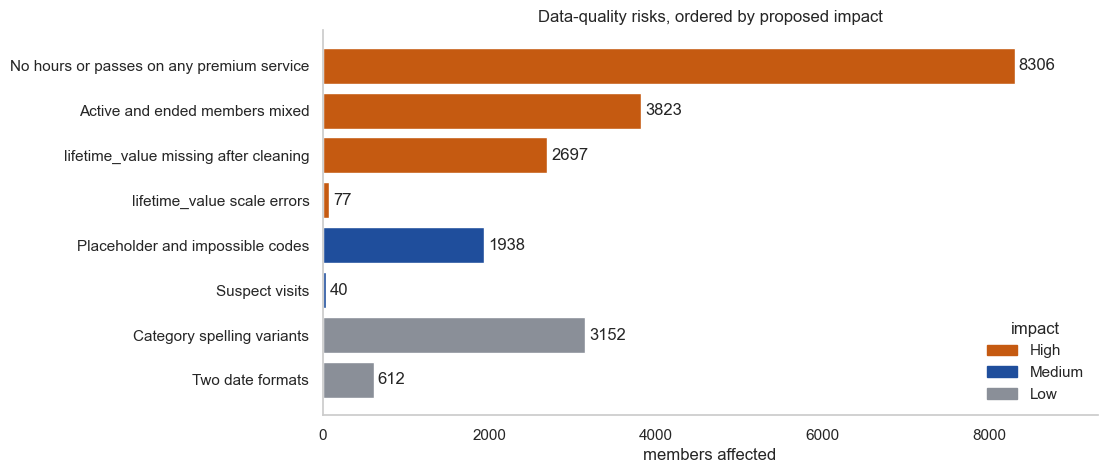

In [54]:
usage_columns = ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]
placeholder_flags = ["flag_age_invalid", "flag_colleagues_placeholder", "flag_plan_days_invalid", "flag_days_since_999"]
suspect_flags = ["flag_visits_scale_error"]
slash_dates = df_raw.loc[df.index, date_features].apply(lambda s: s.str.contains("/", regex=False)).any(axis=1)
top1_before, top1_after = comparison.loc["revenue share of top 1%", ["before", "after"]]

risk_rows = [
    ("lifetime_value scale errors", df["flag_ltv_scale_error"], "High",
     f"Without treatment the top 1% hold {top1_before:.1%} of revenue, against {top1_after:.1%} after it, so value would dominate any distance",
     "Detected relative to the plan, treated and flagged; confirm the cause with ACDC"),
    ("lifetime_value missing after cleaning", df["lifetime_value"].isna(), "High",
     "Members without a value cannot be placed on the value axis",
     "Decide in Deliverable 2 between imputing, a missing indicator or a separate value perspective"),
    ("No hours or passes on any premium service", (df[usage_columns] == 0).all(axis=1), "High",
     "Distances on columns that are mostly zero can create a group of non-users",
     "Use presence flags and measure intensity among users only"),
    ("Active and ended members mixed", df["is_active"], "High",
     "Tenure of active members is censored, so status can look like a behavioural group",
     "Compare within status, or carry status as an explicit variable"),
    ("Suspect visits", df[suspect_flags].any(axis=1), "Medium",
     "A few values that look wrong can stretch the scale of a usage axis",
     "Flagged, not corrected; confirm the possible scale error in visits before modelling"),
    ("Placeholder and impossible codes", df[placeholder_flags].any(axis=1), "Medium",
     "A code read as a real number gives a member a false position",
     "Recovered from another field or set to missing, with one flag per rule"),
    ("Category spelling variants", changed.loc[df.index], "Low",
     "One category would split into several",
     "Mapped to one label with an explicit mapping"),
    ("Two date formats", slash_dates, "Low",
     "A misread date would move a member along the lifecycle axis",
     "Day-first reading checked on the data, then parsed explicitly"),
]
risks = pd.DataFrame(
    [{"risk": r, "members": int(m.sum()), "% of members": round(m.mean() * 100, 1), "impact": i, "effect on clustering": e, "mitigation": g}
     for r, m, i, e, g in risk_rows]
)
impact_rank = {"High": 0, "Medium": 1, "Low": 2}
# Sort by impact first (High to Low), then by the number of affected members
risks = risks.sort_values(["impact", "members"], key=lambda s: s.map(impact_rank) if s.name == "impact" else -s).reset_index(drop=True)
with pd.option_context("display.max_colwidth", None):
    display(risks)

impact_colors = {"High": "#C55A11", "Medium": STATUS_COLORS["active"], "Low": STATUS_COLORS["ended"]}
fig, ax = plt.subplots(figsize=(10, 5))
ordered = risks.iloc[::-1]
bars = ax.barh(ordered["risk"], ordered["members"], color=ordered["impact"].map(impact_colors))
ax.bar_label(bars, labels=[f"{v}" for v in ordered["members"]], padding=3)
ax.set(xlabel="members affected", title="Data-quality risks, ordered by proposed impact", xlim=(0, risks["members"].max() * 1.12))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in impact_colors.values()], labels=list(impact_colors), title="impact", frameon=False, loc="lower right")
ax.grid(False)
sns.despine()
plt.show()

### 6.2 Decisions left for Deliverable 2
None of these is applied in this notebook.

- **Perspectives:** build the value and behaviour segmentations separately and integrate them at the end, as the guidelines ask.
- **Missing values:** the choice between imputing, adding an indicator or using complete cases should be reported, because the gaps are not evenly spread. Two imputations are worth testing. For hours and passes where the `uses_*` flag is True, use the median among users of the same plan, with an indicator of imputed values. For `lifetime_value`, an estimate from the plan price and tenure may work better than a median; it remains a hypothesis.
- **Scaling:** revenue, visits and tenure have long tails and different units, so a distance needs a log or rank view, or standardisation, once the scale errors are treated.
- **Zero-heavy usage columns:** separate whether a service is used from how much it is used.
- **Categorical variables:** `plan_tier` is ordinal, but its order does not match monthly revenue (Section 4.4). Nominal variables need an encoding, or can be kept only to describe the groups.
- **Redundant columns:** `entitled_visits_last_period` appears to follow from plan days and tenure and `lifetime_value` depends mostly on plan and tenure (Section 4.3). Neither should enter a distance alongside the columns it repeats without a stated reason.

### 6.3 Expected groups
These are hypotheses for Deliverable 2. No clustering has been run.

**Conclusions behind these expectations**

- **Most members do not bring most of the value.** `hot_desk` and `flex` hold 69.3% of members but 33.1% of known lifetime value (Section 4.4).
- **Membership length changes a lot with the plan.** The median is 26.6 and 29.7 months on `dedicated_desk` and `private_office`, against 2.6 and 8.6 on `hot_desk` and `flex` (Section 4.4).
- **Value is mostly plan and duration.** Prices are almost fixed per plan and `lifetime_value` has a Spearman correlation of 0.95 with `membership_months` (Sections 4.3 and 4.9).
- **Service use changes with the plan.** `uses_mail_handling` and `uses_storage` are the columns most associated with `plan_tier`, with a Cramér's V of 0.46 and 0.40 (Section 4.9).

**Expected number of groups**

- **Value perspective:** about 3, following the price levels: `hot_desk` and `flex`, then `full_time` and `dedicated_desk`, then `private_office`.
- **Behavioural perspective:** 4 or 5: recent members, members who left early, members who left later, active members who still come and active members who have almost stopped coming (Sections 4.1 and 4.6).

**Features that should separate members most:** `plan_usage_rate`, `membership_months`, `monthly_value`, `number_of_addons_used` and recency within each status.

**Anticipated challenges**

- Clusters may only repeat the plan or the member's life stage (new, active, ended).
- Missing values and scale errors are still to be treated.
- Some variables repeat the same information.

## AI usage statement

**Diogo** used Claude Code, connected to Deepnote through MCP, to brainstorm directions to explore, to investigate data problems in more depth and test conclusions against the data, and to write code to our specification, including reviewing and consolidating the group's earlier code into the final notebook. It was also used to understand each other's code, to organise our reasoning and conclusions into concise Markdown, to produce the slides from a plan the group had defined, and for version control and the READMEs.

**Gustavo** used ChatGPT, connected to Deepnote through MCP, to clarify doubts, to help identify and correct errors in the notebook code (mainly data visualization in seaborn and matplotlib, and syntax in pandas and numpy), and to review grammar and wording so the written explanations were clearer.

**Mohamed** used Qoder for coding help (pandas operations and matplotlib formatting), building the dashboard, brainstorming exploratory customer hypotheses, proofreading and repository work.

Overall, our contribution exceeded that of the AI tools. We used them to write code, check results and analyse large volumes of data faster, to structure our writing and to brainstorm. The group made the final decisions on what to explore, which conclusions to draw and what to include, and takes responsibility for the submitted work.